In [1]:
"""
copied from cnn_training_morestamps, now with more classes and more stamps !

here we are retraining the same architecture of cnn with my new stamps
[the stamps go down to a 1.01x brightness increase now]

mostly copied from best_3_outbook_cnn:
 This notebook will train another 3-output nn, this time using some kind of
dynamic learning rate and also saving the best epoch instead of the last one
"""

'\ncopied from cnn_training_morestamps, now with more classes and more stamps !\n\nhere we are retraining the same architecture of cnn with my new stamps\n[the stamps go down to a 1.01x brightness increase now]\n\nmostly copied from best_3_outbook_cnn:\n This notebook will train another 3-output nn, this time using some kind of\ndynamic learning rate and also saving the best epoch instead of the last one\n'

In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import imageio as iio
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.metrics import confusion_matrix, f1_score
from astropy.io import fits
import scipy.ndimage as snm
from tqdm.auto import tqdm
import os
from pylab import cm
import matplotlib as mpl

2025-02-10 14:52:25.820934: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
fpath_streak = "/lustre/lrspec/ZTF_data/training_aug24/stamps_no_trans/images/"


for i, file in enumerate(os.listdir(fpath_streak)):
    image_filename = os.fsdecode(file)
    image_filename_full = fpath_streak + image_filename
    print(image_filename)
    streak = np.load(image_filename_full)
    streak_arr = np.array(streak)
    print(np.shape(streak))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_streak_stamps = streak_arr
    else:
        all_streak_stamps = np.concatenate((all_streak_stamps, streak_arr), axis=0)

ztf_20221017148750_000831_zi_c02_x_0026._4_stamps.npy
(7, 20, 20)
ztf_20221014162894_000802_zg_c01_x_0014._2_stamps.npy
(8, 20, 20)
ztf_20221017148750_000831_zi_c03_x_0018._3_stamps.npy
(4, 20, 20)
ztf_20220820237546_000798_zr_c14_x_0004._2_stamps.npy
(10, 20, 20)
ztf_20221014162894_000802_zg_c01_x_0021._1_stamps.npy
(10, 20, 20)
ztf_20221020138241_000686_zi_c01_x_0005._4_stamps.npy
(9, 20, 20)
ztf_20221017148750_000831_zi_c03_x_0001._1_stamps.npy
(7, 20, 20)
ztf_20221020138241_000686_zi_c02_x_0001._3_stamps.npy
(10, 20, 20)
ztf_20221020138241_000686_zi_c06_x_0007._4_stamps.npy
(10, 20, 20)
ztf_20221020138241_000686_zi_c07_x_0020._1_stamps.npy
(9, 20, 20)
ztf_20221014162894_000802_zg_c03_x_0002._3_stamps.npy
(6, 20, 20)
ztf_20220820237546_000798_zr_c02_x_0002._3_stamps.npy
(10, 20, 20)
ztf_20221014162894_000802_zg_c02_x_0023._2_stamps.npy
(5, 20, 20)
ztf_20221020138241_000686_zi_c03_x_0015._1_stamps.npy
(9, 20, 20)
ztf_20221014162894_000802_zg_c02_x_0016._1_stamps.npy
(8, 20, 20)
ztf_2

In [4]:
np.shape(all_streak_stamps)

(9715, 20, 20)

In [5]:
fpath_trans = "/lustre/lrspec/ZTF_data/training_aug24/stamps_pos_trans_2/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_pos_stamps = trans_arr
        all_pos_stamps_info = infos_arr
    else:
        all_pos_stamps = np.concatenate((all_pos_stamps, trans_arr), axis=0)
        all_pos_stamps_info = np.concatenate((all_pos_stamps_info, infos_arr), axis=0)

ztf_20221020138241_000686_zi_c05_x_0011._2_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20220820237546_000798_zr_c04_x_0000._4_stamps.npy
(9, 20, 20)
(9, 2)
ztf_20221017148750_000831_zi_c03_x_0026._3_stamps.npy
(4, 20, 20)
(4, 2)
ztf_20221020138241_000686_zi_c02_x_0026._1_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20221014162894_000802_zg_c02_x_0002._4_stamps.npy
(7, 20, 20)
(7, 2)
ztf_20221014162894_000802_zg_c03_x_0010._2_stamps.npy
(6, 20, 20)
(6, 2)
ztf_20220820237546_000798_zr_c07_x_0004._3_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20221017148750_000831_zi_c04_x_0008._2_stamps.npy
(8, 20, 20)
(8, 2)
ztf_20220820237546_000798_zr_c16_x_0000._2_stamps.npy
(8, 20, 20)
(8, 2)
ztf_20221020138241_000686_zi_c02_x_0013._2_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20221020138241_000686_zi_c03_x_0001._4_stamps.npy
(9, 20, 20)
(9, 2)
ztf_20221014162894_000802_zg_c02_x_0028._1_stamps.npy
(8, 20, 20)
(8, 2)
ztf_20220820237546_000798_zr_c09_x_0000._3_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20221017148750_000831_zi_c04_x_0017._

In [6]:
np.shape(all_pos_stamps)

(9715, 20, 20)

In [7]:
np.shape(all_pos_stamps)

(9715, 20, 20)

In [8]:
fpath_cr = "/lustre/lrspec/ZTF_data/training_aug24/stamps_cr/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

for i, file in enumerate(os.listdir(fpath_cr)):
    image_filename = os.fsdecode(file)
    image_filename_full = fpath_cr + image_filename
    print(image_filename)
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    print(np.shape(trans))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_cr_stamps = trans
    else:
        all_cr_stamps = np.concatenate((all_cr_stamps, trans_arr), axis=0)

cr_1017.npy
(150, 20, 20)
cr_1014.npy
(150, 20, 20)
cr_0820.npy
(150, 20, 20)
cr_1020.npy
(150, 20, 20)


In [9]:
np.shape(all_cr_stamps)

(600, 20, 20)

In [10]:
fpath_trans = "/lustre/lrspec/ZTF_data/training_aug24/stamps_neg_trans_2/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_neg_stamps = trans_arr
        all_neg_stamps_info = infos_arr
    else:
        all_neg_stamps = np.concatenate((all_neg_stamps, trans_arr), axis=0)
        all_neg_stamps_info = np.concatenate((all_neg_stamps_info, infos_arr), axis=0)

ztf_20221017148750_000831_zi_c01_x_0009._2_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20221014162894_000802_zg_c03_x_0005._3_stamps.npy
(6, 20, 20)
(6, 2)
ztf_20220820237546_000798_zr_c13_x_0001._2_stamps.npy
(7, 20, 20)
(7, 2)
ztf_20221020138241_000686_zi_c05_x_0028._2_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20220820237546_000798_zr_c14_x_0003._2_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20221020138241_000686_zi_c01_x_0002._4_stamps.npy
(9, 20, 20)
(9, 2)
ztf_20221017148750_000831_zi_c02_x_0021._4_stamps.npy
(7, 20, 20)
(7, 2)
ztf_20220820237546_000798_zr_c01_x_0001._4_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20221014162894_000802_zg_c01_x_0013._2_stamps.npy
(8, 20, 20)
(8, 2)
ztf_20221020138241_000686_zi_c01_x_0028._1_stamps.npy
(10, 20, 20)
(10, 2)
ztf_20221014162894_000802_zg_c02_x_0011._1_stamps.npy
(8, 20, 20)
(8, 2)
ztf_20221014162894_000802_zg_c02_x_0008._3_stamps.npy
(9, 20, 20)
(9, 2)
ztf_20221017148750_000831_zi_c04_x_0009._3_stamps.npy
(6, 20, 20)
(6, 2)
ztf_20221014162894_000802_zg_c03_x_0011._

In [11]:
np.shape(all_neg_stamps)

(9715, 20, 20)

In [12]:
fpath_bg = "/lustre/lrspec/ZTF_data/training_aug24/stamps_background/images/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

for i, file in enumerate(os.listdir(fpath_bg)):
    image_filename = os.fsdecode(file)
    image_filename_full = fpath_bg + image_filename
    print(image_filename)
    bg = np.load(image_filename_full)
    bg_arr = np.array(bg)
    print(np.shape(bg))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_bg_stamps = bg
    else:
        all_bg_stamps = np.concatenate((all_bg_stamps, bg_arr), axis=0)

    # all_trans_stamps[i] = trans
# neg_stamps = all_bg_stamps

ztf_20221014162894_000802_zg_c02_x_0002._4_background_stamps.npy
(18, 20, 20)
ztf_20221014162894_000802_zg_c01_x_0029._1_background_stamps.npy
(23, 20, 20)
ztf_20220820237546_000798_zr_c07_x_0002._4_background_stamps.npy
(25, 20, 20)
ztf_20220820237546_000798_zr_c13_x_0001._4_background_stamps.npy
(17, 20, 20)
ztf_20221020138241_000686_zi_c01_x_0009._1_background_stamps.npy
(23, 20, 20)
ztf_20221014162894_000802_zg_c02_x_0003._2_background_stamps.npy
(22, 20, 20)
ztf_20220820237546_000798_zr_c07_x_0003._2_background_stamps.npy
(29, 20, 20)
ztf_20220820237546_000798_zr_c14_x_0002._3_background_stamps.npy
(20, 20, 20)
ztf_20221017148750_000831_zi_c04_x_0007._1_background_stamps.npy
(32, 20, 20)
ztf_20221020138241_000686_zi_c05_x_0021._3_background_stamps.npy
(20, 20, 20)
ztf_20221020138241_000686_zi_c07_x_0017._3_background_stamps.npy
(24, 20, 20)
ztf_20221017148750_000831_zi_c02_x_0017._4_background_stamps.npy
(25, 20, 20)
ztf_20220820237546_000798_zr_c02_x_0004._3_background_stamps.npy

In [13]:
np.shape(all_bg_stamps)

(24382, 20, 20)

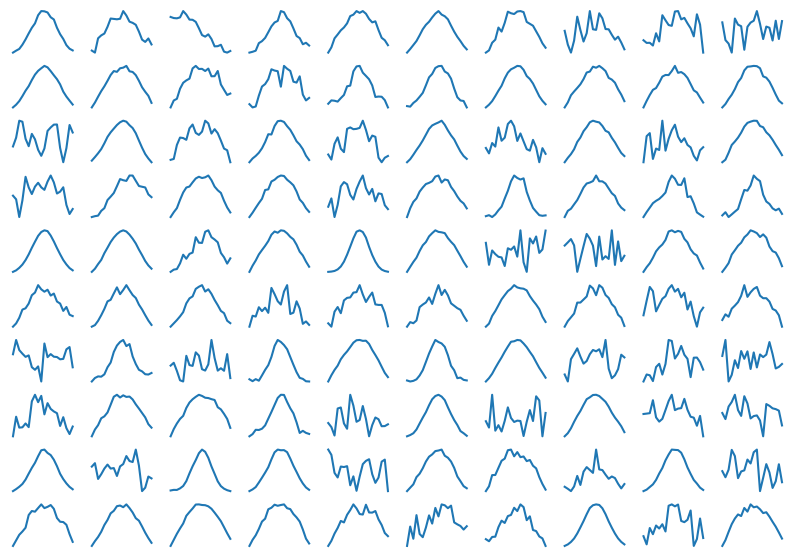

In [14]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(all_pos_stamps[i * 10 + h], axis=1))
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].axis("off")
fig.show()

In [16]:
all_pos_stamps_info[:, 0]

array([ 3.  ,  1.5 ,  1.01, ..., 10.  ,  1.3 ,  2.  ])

In [14]:
# Combine all features
feat = np.concatenate(
    (all_bg_stamps, all_pos_stamps, all_neg_stamps, all_cr_stamps, all_streak_stamps),
    axis=0,
)

# Split features into training and testing sets once
feat_tr, feat_te = train_test_split(feat, random_state=302)

# Reshape features for the CNN
feat_tr = feat_tr.reshape(feat_tr.shape[0], feat_tr.shape[1], feat_tr.shape[2], 1)
feat_te = feat_te.reshape(feat_te.shape[0], feat_te.shape[1], feat_te.shape[2], 1)

# Process bness and lens separately after the split
bness = np.concatenate(
    (
        np.full(len(all_bg_stamps), 0),
        all_pos_stamps_info[:, 0],
        all_neg_stamps_info[:, 0],
        np.full(len(all_cr_stamps), 0),
        np.full(len(all_streak_stamps), 0),
    )
)

lens = np.concatenate(
    (
        np.full(len(all_bg_stamps), 0),
        all_pos_stamps_info[:, 1],
        all_neg_stamps_info[:, 1],
        np.full(len(all_cr_stamps), 0),
        np.full(len(all_streak_stamps), 0),
    )
)

targ = np.concatenate(
    (
        np.full(len(all_bg_stamps), 0),
        np.full(len(all_pos_stamps), 1),
        np.full(len(all_neg_stamps), 2),
        np.full(len(all_cr_stamps), 3),
        np.full(len(all_streak_stamps), 4),
    )
)

# Split targets and additional variables
bness_tr, bness_te = train_test_split(bness, random_state=302)
lens_tr, lens_te = train_test_split(lens, random_state=302)
targ_tr, targ_te = train_test_split(targ, random_state=302)

# One-hot encode the target variable
targ_tr_one_hot = to_categorical(targ_tr, num_classes=5)
targ_te_one_hot = to_categorical(targ_te, num_classes=5)

In [70]:
targ_tr_one_hot

array([[1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0.]], dtype=float32)

In [22]:
lens_tr

array([0., 4., 7., ..., 0., 0., 0.])

In [25]:
from sklearn.model_selection import KFold
import numpy as np


# adaptive learning rate
def adapt_learning_rate(epoch):
    if epoch < 25:
        return 0.001
    elif epoch < 50:
        return 0.0005
    elif epoch < 80:
        return 0.0001
    elif epoch < 110:
        return 0.00005
    elif epoch < 150:
        return 0.00001
    else:
        return 0.000005
    # let's just test that out and see how it is


# note: default Adam learning rate is 0.001

my_lr_scheduler = keras.callbacks.LearningRateScheduler(adapt_learning_rate)

# early stopping callback
earlystopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", min_delta=0.001, patience=40, restore_best_weights=True
)
# This callback will stop the training when there is no improvement in
# the loss for 30 consecutive epochs.
# also will restore the best weights instead of the most recent

wid = 10

# -- build a simple CNN
layer1 = keras.layers.Conv2D(
    16,
    kernel_size=(5, 5),
    padding="same",
    activation="relu",
    input_shape=(2 * wid, 2 * wid, 1),
    kernel_regularizer=keras.regularizers.l2(0.05),
)
layer2 = keras.layers.MaxPool2D(2)  # changed from 2
layer3 = keras.layers.Conv2D(
    32,
    kernel_size=(3, 3),
    padding="same",
    activation="relu",
    kernel_regularizer=keras.regularizers.l2(0.06),
)
layer9 = keras.layers.Conv2D(
    32,
    kernel_size=(3, 3),
    padding="same",
    activation="relu",
    kernel_regularizer=keras.regularizers.l2(0.06),
)
layer4 = keras.layers.MaxPool2D(2)  # changed from 2
# layer31 = keras.layers.Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu", kernel_regularizer=keras.regularizers.l2(0.06))
# layer91 = keras.layers.Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu", kernel_regularizer=keras.regularizers.l2(0.06))
# layer41 = keras.layers.MaxPool2D(2) #changed from 2
layer5 = keras.layers.Flatten()
layer6 = keras.layers.Dense(
    300, activation="relu"
)  # ,kernel_regularizer=keras.regularizers.l2(0.05))
layer7 = keras.layers.Dense(128, activation="relu")
layer71 = keras.layers.Dense(64, activation="relu")
layer72 = keras.layers.Dense(32, activation="relu")
layer8 = keras.layers.Dense(5, activation="softmax")
layers = [
    layer1,
    layer2,
    layer3,
    layer9,
    layer4,
    layer5,
    layer6,
    layer7,
    layer71,
    layer72,
    layer8,
]

# Parameters
n_splits = 5  # Number of folds for cross-validation

# Initialize KFold
kf = KFold(n_splits=n_splits, shuffle=True, random_state=302)

# Initialize lists to store training and validation results
train_acc_list = []
val_acc_list = []

for fold, (train_idx, val_idx) in enumerate(kf.split(feat_tr)):
    print(f"Training fold {fold + 1}/{n_splits}...")

    # Split the data into training and validation sets for this fold
    feat_tr_fold, feat_val_fold = feat_tr[train_idx], feat_tr[val_idx]
    targ_tr_fold, targ_val_fold = targ_tr_one_hot[train_idx], targ_tr_one_hot[val_idx]

    # Build a new model for each fold
    model = keras.Sequential(layers)
    model.compile(
        optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"]
    )

    # Fit the model
    history = model.fit(
        feat_tr_fold,
        targ_tr_fold,
        epochs=1000,
        validation_data=(feat_val_fold, targ_val_fold),
        batch_size=5,
        callbacks=[earlystopping, my_lr_scheduler],
    )

    # Evaluate the model on the validation set
    loss_val, acc_val = model.evaluate(feat_val_fold, targ_val_fold)
    loss_tr, acc_tr = model.evaluate(feat_tr_fold, targ_tr_fold)

    # Store the results
    train_acc_list.append(acc_tr)
    val_acc_list.append(acc_val)
    print(f"Fold {fold + 1} - Validation accuracy: {acc_val:.4f}")
    print(f"Fold {fold + 1} - Training accuracy: {acc_tr:.4f}")

# Calculate and print the average accuracy across all folds
avg_train_acc = np.mean(train_acc_list)
avg_val_acc = np.mean(val_acc_list)
print(f"\nAverage Training accuracy : {avg_train_acc:.4f}")
print(f"Average Validation accuracy : {avg_val_acc:.4f}")

Training fold 1/5...


2024-09-02 14:52:07.839421: I tensorflow/core/common_runtime/process_util.cc:146] Creating new thread pool with default inter op setting: 2. Tune using inter_op_parallelism_threads for best performance.


Epoch 1/1000
 671/6496 [==>...........................] - ETA: 7:37 - loss: 1.9926 - accuracy: 0.6221

KeyboardInterrupt: 

In [ ]:
model.save("CNN_sept2")

In [16]:
np.save("/home/3155/sept2_loss_history", history.history["loss"])

In [17]:
np.save("/home/3155/sept2_val_loss_history", history.history["val_loss"])
np.save("/home/3155/sept2_accuracy_history", history.history["accuracy"])
np.save("/home/3155/sept2_val_accuracy_history", history.history["val_accuracy"])

In [ ]:
print("DONE TRAINING")

In [26]:
print(x)

NameError: name 'x' is not defined

In [38]:
loss = np.load("/home/3155/sept3_loss_history.npy")

In [39]:
val_loss = np.load("/home/3155/sept3_val_loss_history.npy")
accuracy = np.load("/home/3155/sept3_accuracy_history.npy")
val_accuracy = np.load("/home/3155/sept3_val_accuracy_history.npy")

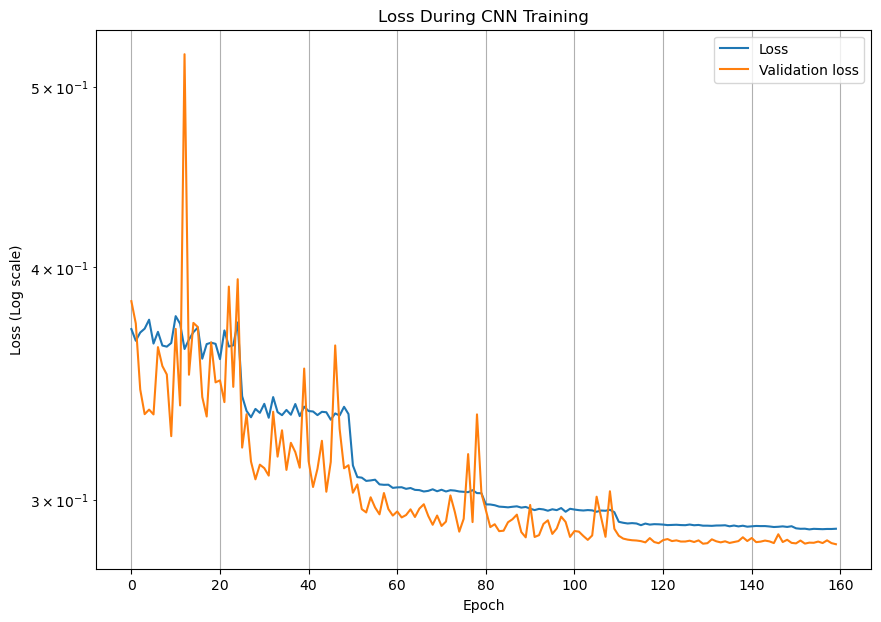

In [40]:
plt.plot(loss)
plt.plot(val_loss)
plt.yscale("log")
plt.legend(["Loss", "Validation loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss (Log scale)")
plt.title("Loss During CNN Training")
# plt.xlim(0,45)
plt.grid()
# plt.xlim(50,90)
# plt.ylim(.25, .35)

# plt.savefig("/home/3155/CNN_best_overfit_longer_200_training_3_outputs/loss_short")

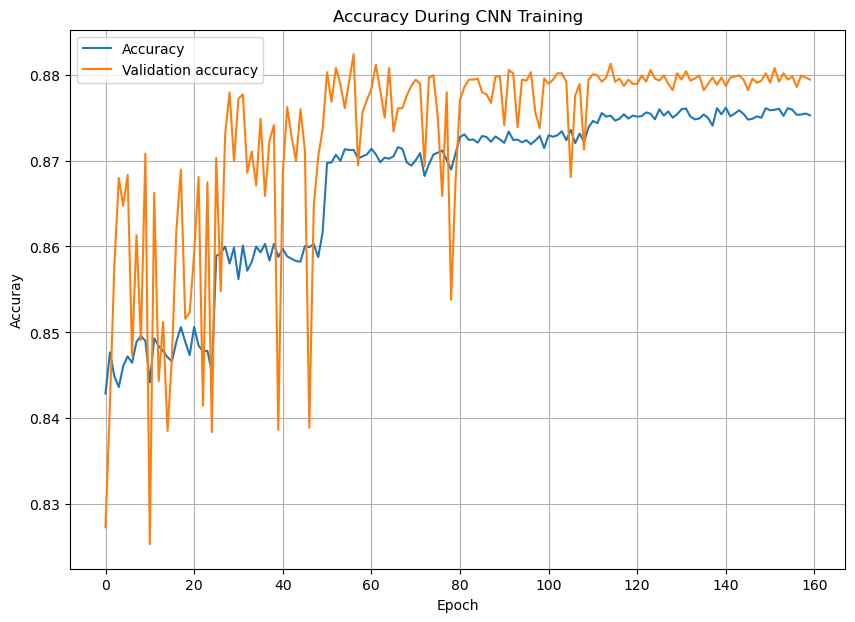

In [41]:
# -- plot the accuracy
plt.plot(accuracy)
plt.plot(val_accuracy)
# plt.plot(np.add(np.array(history.history["accuracy"]),np.array(history.history["val_accuracy"])))
# plt.plot(np.divide(np.array(history.history["val_accuracy"]),np.array(history.history["accuracy"])))
plt.legend(["Accuracy", "Validation accuracy", "ratio val_accuracy/accuracy"])
plt.ylabel("Accuray")
plt.xlabel("Epoch")
plt.title("Accuracy During CNN Training")
# plt.xlim(120,160)
# plt.xlim(50,90)
# plt.ylim(.85, .92)
plt.grid(markevery=5)
# plt.savefig("/home/3155/CNN_best_overfit_longer_200_training_3_outputs/ratio_accuracy_short_early")

In [ ]:
# okay we're going with 85

In [29]:
# model.save("CNN_overfit_200_training_3_outputs")

INFO:tensorflow:Assets written to: CNN_overfit_200_training_3_outputs/assets


INFO:tensorflow:Assets written to: CNN_overfit_200_training_3_outputs/assets


In [13]:
# model = keras.models.load_model("/home/3155/jan_model00000085.h5")

(0.0, 50.0)

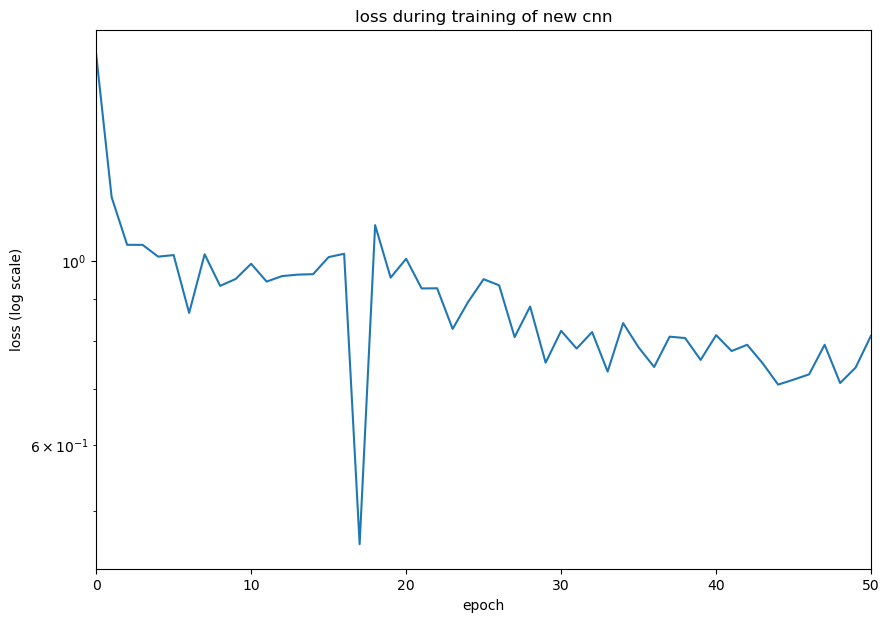

In [33]:
# plt.plot(history.history["loss"])
# plt.plot(history.history["val_loss"])
plt.plot(
    np.divide(np.array(history.history["loss"]), np.array(history.history["val_loss"]))
)
plt.yscale("log")
# plt.legend(["loss","val_loss"])
plt.xlabel("epoch")
plt.ylabel("loss (log scale)")
plt.title("loss during training of new cnn")
plt.xlim(0, 50)

In [15]:
model = keras.models.load_model("/home/3155/CNN_sept2")

2025-02-10 14:59:08.326524: I tensorflow/core/common_runtime/process_util.cc:146] Creating new thread pool with default inter op setting: 2. Tune using inter_op_parallelism_threads for best performance.


In [24]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 20, 20, 16)        416       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 10, 10, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 10, 10, 32)        4640      
                                                                 
 conv2d_2 (Conv2D)           (None, 10, 10, 32)        9248      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 32)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 800)               0

In [16]:
label_pred_te = model.predict(feat_te)

423/423 [==============================] - 7s 15ms/step


In [71]:
label_pred_te

array([[2.2402378e-04, 3.4983460e-02, 3.7361637e-01, 6.2395110e-14,
        5.9117609e-01],
       [1.0000000e+00, 1.1800572e-09, 2.1676042e-19, 2.2370184e-18,
        6.8285746e-15],
       [1.0000000e+00, 4.7823560e-16, 0.0000000e+00, 4.6242046e-21,
        7.2842437e-31],
       ...,
       [3.5864315e-36, 1.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00],
       [1.0000000e+00, 3.4108531e-24, 0.0000000e+00, 1.3189598e-24,
        0.0000000e+00],
       [1.0000000e+00, 3.1330099e-08, 1.7517948e-18, 4.5002364e-18,
        1.4526195e-13]], dtype=float32)

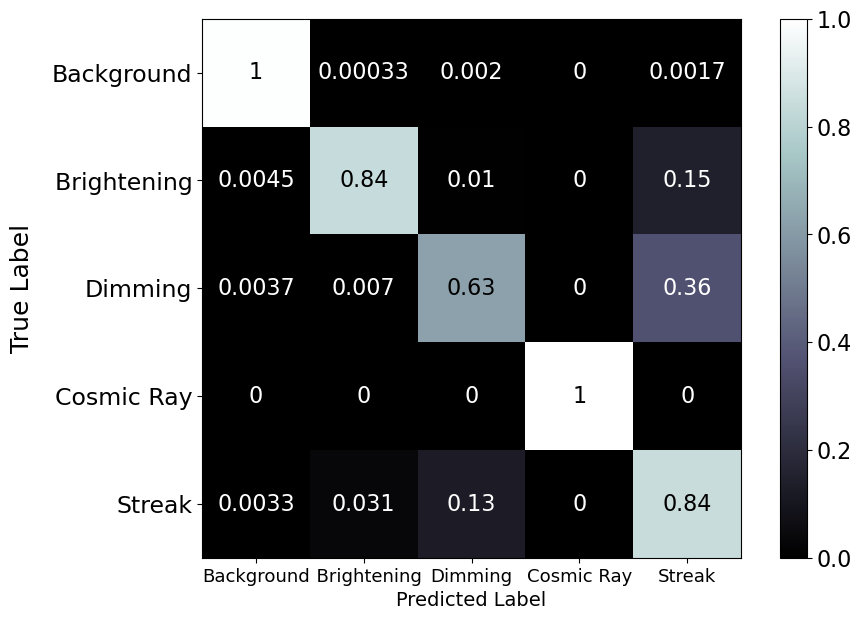

In [64]:
disp = ConfusionMatrixDisplay.from_predictions(
    targ_te,
    np.argmax(label_pred_te, axis=1),
    display_labels=["Background", "  Brightening", "Dimming", "Cosmic Ray", "Streak"],
    cmap="bone",
    normalize="true",
)

# Adjust tick label size
disp.ax_.tick_params(axis="y", labelsize=17)
disp.ax_.tick_params(axis="x", labelsize=13)

# Adjust font size of numbers
for text in disp.ax_.texts:  # Access text annotations
    text.set_fontsize(16)  # Set desired font size
disp.ax_.set_xlabel("Predicted Label", fontsize=14)  # Adjust X-axis label
disp.ax_.set_ylabel("True Label", fontsize=18)  # Adjust Y-axis label

cbar = disp.im_.colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=16)  # Adjust tick label size

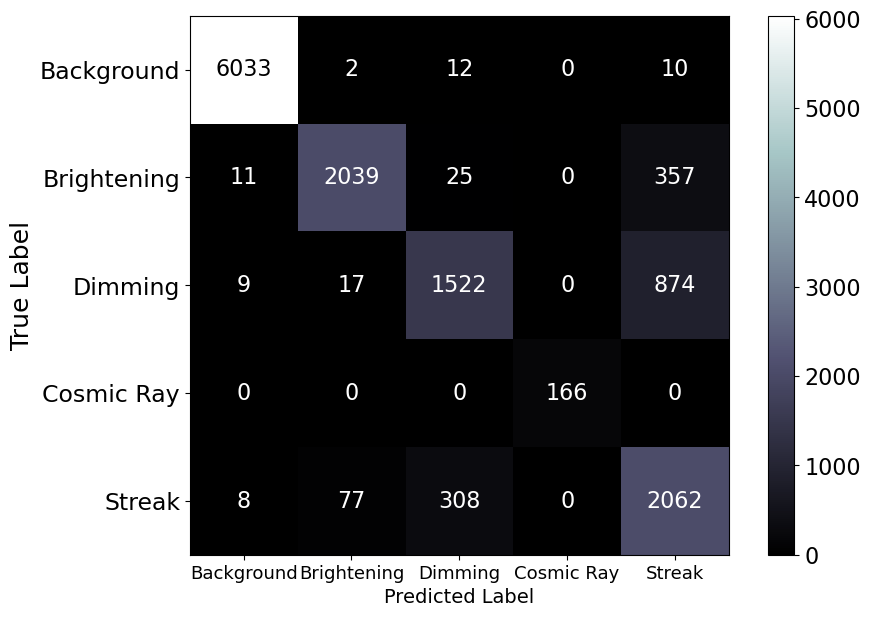

In [65]:
disp = ConfusionMatrixDisplay.from_predictions(
    targ_te,
    np.argmax(label_pred_te, axis=1),
    display_labels=["Background", "Brightening", "Dimming", "Cosmic Ray", "Streak"],
    cmap="bone",
    normalize=None,
)

# Adjust tick label size
disp.ax_.tick_params(axis="y", labelsize=17)
disp.ax_.tick_params(axis="x", labelsize=13)

# Adjust font size of numbers
for text in disp.ax_.texts:  # Access text annotations
    text.set_fontsize(16)  # Set desired font size
disp.ax_.set_xlabel("Predicted Label", fontsize=14)  # Adjust X-axis label
disp.ax_.set_ylabel("True Label", fontsize=18)  # Adjust Y-axis label

cbar = disp.im_.colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=16)  # Adjust tick label size

In [46]:
f1_score(targ_te, np.argmax(label_pred_te, axis=1), average=None)

array([0.99570886, 0.89292752, 0.70972255, 1.        , 0.71622091])

In [17]:
targ_te == 1
np.argmax(label_pred_te, axis=1) == 1
targ_te[np.argmax(label_pred_te, axis=1) == 1]  # targets where label is 1
np.sum(targ_te[np.argmax(label_pred_te, axis=1) != 1] == 1)

393

In [18]:
nlabel_pred_te = label_pred_te[bness_te < 0.95]
plabel_pred_te = label_pred_te[bness_te > 1.05]

In [19]:
label_pred_te[:, 1] > 0.9999

array([False, False, False, ...,  True, False, False])

In [20]:
thr = 0.9999
tp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] == 1)
fp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] != 1)
fn_thr = np.sum(targ_te[label_pred_te[:, 1] < thr] == 1)

In [21]:
precision_thr = tp_thr / (tp_thr + fp_thr)
recall_thr = tp_thr / (tp_thr + fn_thr)
print(precision_thr, recall_thr)

1.0 0.6953125


In [22]:
tp = np.sum(targ_te[np.argmax(label_pred_te, axis=1) == 1] == 1)
fp = np.sum(targ_te[np.argmax(label_pred_te, axis=1) == 1] != 1)
fn = np.sum(targ_te[np.argmax(label_pred_te, axis=1) != 1] == 1)

In [35]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)
print(precision, recall)

0.9550351288056206 0.8384046052631579


In [23]:
tp = np.sum(targ_te[np.argmax(label_pred_te, axis=1) == 2] == 2)
fp = np.sum(targ_te[np.argmax(label_pred_te, axis=1) == 2] != 2)
fn = np.sum(targ_te[np.argmax(label_pred_te, axis=1) != 2] == 2)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
print(precision, recall)

0.8152115693626139 0.6284062758051198


In [24]:
thr = 0.9999
tp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] == 2)
fp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] != 2)
fn_thr = np.sum(targ_te[label_pred_te[:, 2] < thr] == 2)
precision_thr = tp_thr / (tp_thr + fp_thr)
recall_thr = tp_thr / (tp_thr + fn_thr)
print(precision_thr, recall_thr)

0.9958071278825996 0.19611890999174236


In [25]:
threshes = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.995, 0.9999]
threshes = np.linspace(0.1, 0.9999, 50)

In [26]:
prec_br = []
prec_dim = []
rec_br = []
rec_dim = []
for thr in threshes:
    tp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] == 1)
    fp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] != 1)
    fn_thr = np.sum(targ_te[label_pred_te[:, 1] < thr] == 1)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_br.append(precision_thr)
    rec_br.append(recall_thr)
    tp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] == 2)
    fp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] != 2)
    fn_thr = np.sum(targ_te[label_pred_te[:, 2] < thr] == 2)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_dim.append(precision_thr)
    rec_dim.append(recall_thr)

In [27]:
rec_br

[0.9486019736842105,
 0.9403782894736842,
 0.930921052631579,
 0.9235197368421053,
 0.9148848684210527,
 0.9058388157894737,
 0.8992598684210527,
 0.8943256578947368,
 0.8889802631578947,
 0.8836348684210527,
 0.8778782894736842,
 0.8717105263157895,
 0.8680098684210527,
 0.8643092105263158,
 0.858141447368421,
 0.8523848684210527,
 0.8453947368421053,
 0.8408717105263158,
 0.8396381578947368,
 0.834703947368421,
 0.8297697368421053,
 0.8256578947368421,
 0.8211348684210527,
 0.8166118421052632,
 0.8125,
 0.8092105263157895,
 0.8050986842105263,
 0.8026315789473685,
 0.8018092105263158,
 0.7985197368421053,
 0.795641447368421,
 0.7931743421052632,
 0.7907072368421053,
 0.7894736842105263,
 0.7882401315789473,
 0.7874177631578947,
 0.7865953947368421,
 0.7845394736842105,
 0.7828947368421053,
 0.7808388157894737,
 0.7791940789473685,
 0.7767269736842105,
 0.7730263157894737,
 0.7693256578947368,
 0.7639802631578947,
 0.7602796052631579,
 0.7537006578947368,
 0.7462993421052632,
 0.73273

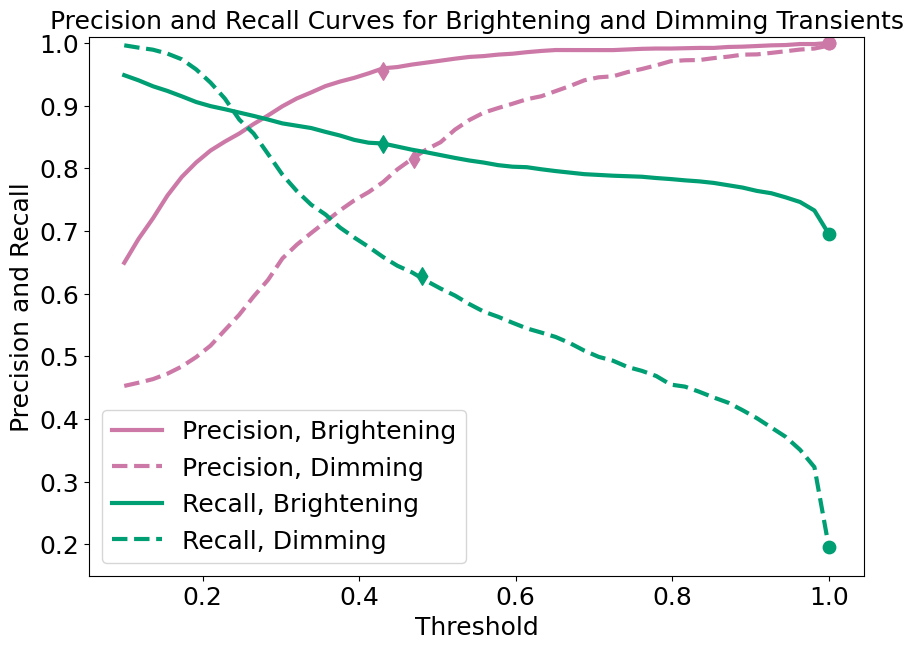

In [50]:
plt.plot(threshes, prec_br, label="Precision, Brightening", linewidth=3, c="#cc79a7")
plt.plot(
    threshes,
    prec_dim,
    label="Precision, Dimming",
    linewidth=3,
    linestyle="dashed",
    c="#cc79a7",
)
plt.plot(threshes, rec_br, label="Recall, Brightening", linewidth=3, c="#009e73")
plt.plot(
    threshes,
    rec_dim,
    label="Recall, Dimming",
    linewidth=3,
    linestyle="dashed",
    c="#009e73",
)
# plt.plot(threshes, np.full( len(threshes), 0.9550351288056206), label="Precision Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8384046052631579), label="Recall Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8152115693626139), label="Precision Dimming Max")
# plt.plot(threshes, np.full( len(threshes), 0.6284062758051198), label="Recall Dimming Max")
plt.scatter(0.43, 0.9550351288056206, s=80, marker="d", c="#cc79a7")
plt.scatter(0.47, 0.8152115693626139, s=80, marker="d", c="#cc79a7")
plt.scatter(0.43, 0.8384046052631579, s=80, marker="d", c="#009e73")

plt.scatter(0.48, 0.6284062758051198, s=80, marker="d", c="#009e73")

plt.scatter(0.9999, 1, s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, 1, s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, 0.695, s=80, marker="o", c="#009e73")
plt.scatter(0.9999, 0.196, s=80, marker="o", c="#009e73")

plt.legend(fontsize=18)
plt.title(
    "Precision and Recall Curves for Brightening and Dimming Transients", fontsize=18
)
plt.xlabel("Threshold", fontsize=18)
plt.ylabel("Precision and Recall", fontsize=18)
plt.ylim(0.15, 1.01)
plt.tick_params(axis="both", labelsize=18)

In [97]:
targ_te[all(0 < bness_te < 0.95)]

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [33]:
nlabel_pred_te = label_pred_te[bness_te < 0.9]
plabel_pred_te = label_pred_te[bness_te > 1.03]
ntarg_te = targ_te[bness_te < 0.9]
ptarg_te = targ_te[bness_te > 1.03]

prec_br = []
prec_dim = []
rec_br = []
rec_dim = []
for thr in threshes:
    tp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] == 1)
    fp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] != 1)
    fn_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] < thr] == 1)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_br.append(precision_thr)
    rec_br.append(recall_thr)
    tp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] == 2)
    fp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] != 2)
    fn_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] < thr] == 2)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_dim.append(precision_thr)
    rec_dim.append(recall_thr)

In [117]:
# threshes = [.1,.2,.3,.4,.5,.6,.7,.8,.9, .99, .9999]

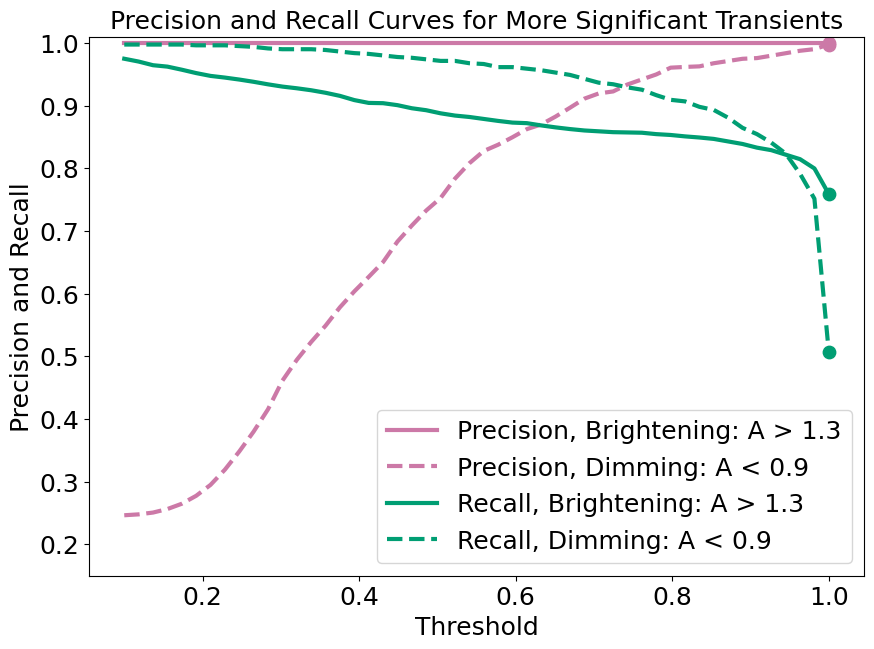

In [48]:
plt.plot(
    threshes, prec_br, label="Precision, Brightening: A > 1.3", linewidth=3, c="#cc79a7"
)
plt.plot(
    threshes,
    prec_dim,
    label="Precision, Dimming: A < 0.9",
    linewidth=3,
    linestyle="dashed",
    c="#cc79a7",
)
plt.plot(
    threshes, rec_br, label="Recall, Brightening: A > 1.3", linewidth=3, c="#009e73"
)
plt.plot(
    threshes,
    rec_dim,
    label="Recall, Dimming: A < 0.9",
    linewidth=3,
    linestyle="dashed",
    c="#009e73",
)
# plt.plot(threshes, np.full( len(threshes), 0.9550351288056206), label="Precision Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8384046052631579), label="Recall Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8152115693626139), label="Precision Dimming Max")
# plt.plot(threshes, np.full( len(threshes), 0.6284062758051198), label="Recall Dimming Max")
# plt.scatter(.43,  0.9550351288056206,  s=80, marker='d', c='#cc79a7')
# plt.scatter(.47,  0.8152115693626139,  s=80, marker='d', c='#cc79a7')
# plt.scatter(.43,  0.8384046052631579,  s=80, marker='d', c='#009e73')

plt.scatter(0.9999, prec_br[-1], s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, prec_dim[-1], s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, rec_br[-1], s=80, marker="o", c="#009e73")
plt.scatter(0.9999, rec_dim[-1], s=80, marker="o", c="#009e73")

plt.legend(fontsize=18)
plt.title("Precision and Recall Curves for More Significant Transients", fontsize=18)
plt.xlabel("Threshold", fontsize=18)
plt.ylabel("Precision and Recall", fontsize=18)
plt.ylim(0.15, 1.01)
plt.tick_params(axis="both", labelsize=18)

In [47]:
np.shape(all_neg_stamps_info)

(9715, 2)

In [43]:
np.shape(np.zeros((np.shape(all_bg_stamps)[0], 2)))

(24382, 2)

In [19]:
np.shape(targ_te)

(13532,)

In [67]:
feat_te_info[:, 0]

array([0.99, 0.  , 0.  , ..., 4.  , 0.  , 0.  ])

In [125]:
np.unique(all_pos_stamps_info[:, 0])

array([ 1.01,  1.05,  1.1 ,  1.3 ,  1.5 ,  2.  ,  3.  ,  4.  ,  6.  ,
        8.  , 10.  ])

In [ ]:
# okay so feat_te_info contains the information

In [65]:
all_pos_stamps_info[1]

array([10.,  8.])

In [ ]:
# brightness, length

In [30]:
our_feat_te = feat_te[bness_te > 0]

In [31]:
our_bness_te = bness_te[bness_te > 0]

In [32]:
our_lens_te = lens_te[bness_te > 0]

In [33]:
our_bness_te

array([ 0.995,  1.01 ,  0.8  , ...,  1.05 ,  1.3  , 10.   ])

In [41]:
our_pred_te_max = np.argmax(label_pred_te[bness_te > 0], axis=1)

In [35]:
our_targ_te = targ_te[bness_te > 0]

In [36]:
np.shape(our_targ_te)

(4854,)

In [37]:
# info = np.load('/lustre/lrspec/ZTF_data/training_aug24/stamps_neg_trans/info/ztf_20221020138241_000686_zi_c08_x_0024._4_stamps_info.npy')

In [38]:
our_feat_te_p8 = our_feat_te[our_outs_te == 0.8]

NameError: name 'our_outs_te' is not defined

In [39]:
label_pred_te

array([[2.2402358e-04, 3.4983490e-02, 3.7361595e-01, 6.2395503e-14,
        5.9117645e-01],
       [1.0000000e+00, 1.1800572e-09, 2.1675049e-19, 2.2370184e-18,
        6.8284705e-15],
       [1.0000000e+00, 4.7823925e-16, 0.0000000e+00, 4.6241690e-21,
        7.2842992e-31],
       ...,
       [3.5864315e-36, 1.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00],
       [1.0000000e+00, 3.4109052e-24, 0.0000000e+00, 1.3189598e-24,
        0.0000000e+00],
       [1.0000000e+00, 3.1329623e-08, 1.7516877e-18, 4.5002364e-18,
        1.4525752e-13]], dtype=float32)

In [43]:
trues = []
fails = []
for i in range(len(our_targ_te)):
    if our_targ_te[i] == our_label_pred_te_max[i]:
        trues.append(our_feat_te_info[i])
    else:
        fails.append(our_feat_te_info[i])
fails = np.array(fails)
trues = np.array(trues)

NameError: name 'our_label_pred_te_max' is not defined

In [42]:
our_pred_te_max[:10]

array([4, 4, 2, 2, 4, 1, 4, 1, 1, 1])

In [48]:
trues = []
fails = []
for i in range(len(our_targ_te)):
    if our_targ_te[i] == our_pred_te_max[i]:
        trues.append([our_bness_te[i], our_lens_te[i]])
    else:
        fails.append([our_bness_te[i], our_lens_te[i]])
fails = np.array(fails)
trues = np.array(trues)

In [49]:
our_feat_te_pos = feat_te[bness_te > 1]
our_feat_te_pos = our_feat_te[bness_te < 1.06]

our_bness_te_pos = outs_te[bness_te > 0]
our_bness_te_pos = our_bness_te_pos[bness_te > 0]

our_targ_te = targ_te[bness_te > 0]

our_pred_te_max = np.argmax(label_pred_te[bness_te > 0], axis=1)

IndexError: boolean index did not match indexed array along dimension 0; dimension is 4854 but corresponding boolean dimension is 13532

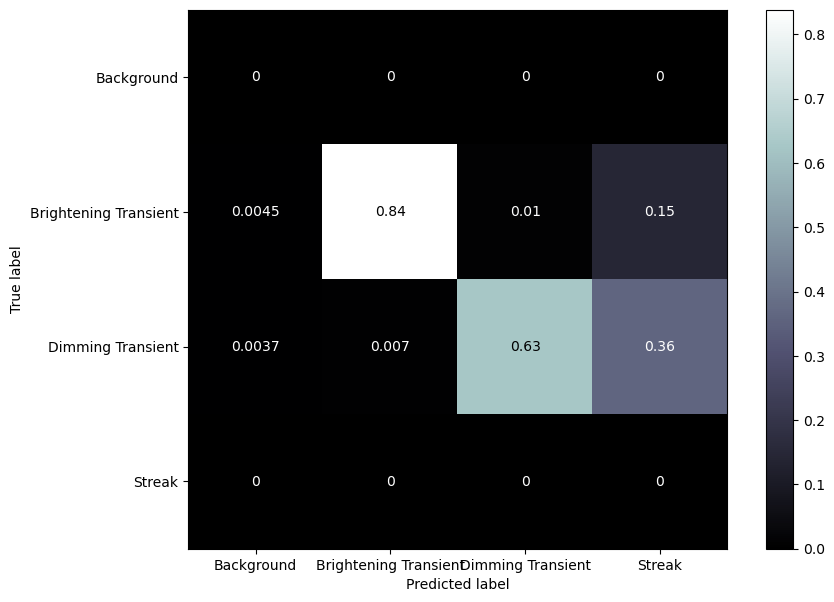

In [61]:
ConfusionMatrixDisplay.from_predictions(
    our_targ_te,
    our_pred_te_max,
    display_labels=[
        "Background",
        "Brightening Transient",
        "Dimming Transient",
        "Streak",
    ],  # "Cosmic Ray",
    cmap="bone",
    normalize="true",
)

In [292]:
len(trues)

3566

In [293]:
len(fails)

1288

In [28]:
import seaborn as sns

In [65]:
np.unique(our_feat_te_info[:, 1])

NameError: name 'our_feat_te_info' is not defined

In [47]:
trues

[]

In [46]:
np.unique(our_lens_te)

array([3., 4., 5., 6., 7., 8., 9.])

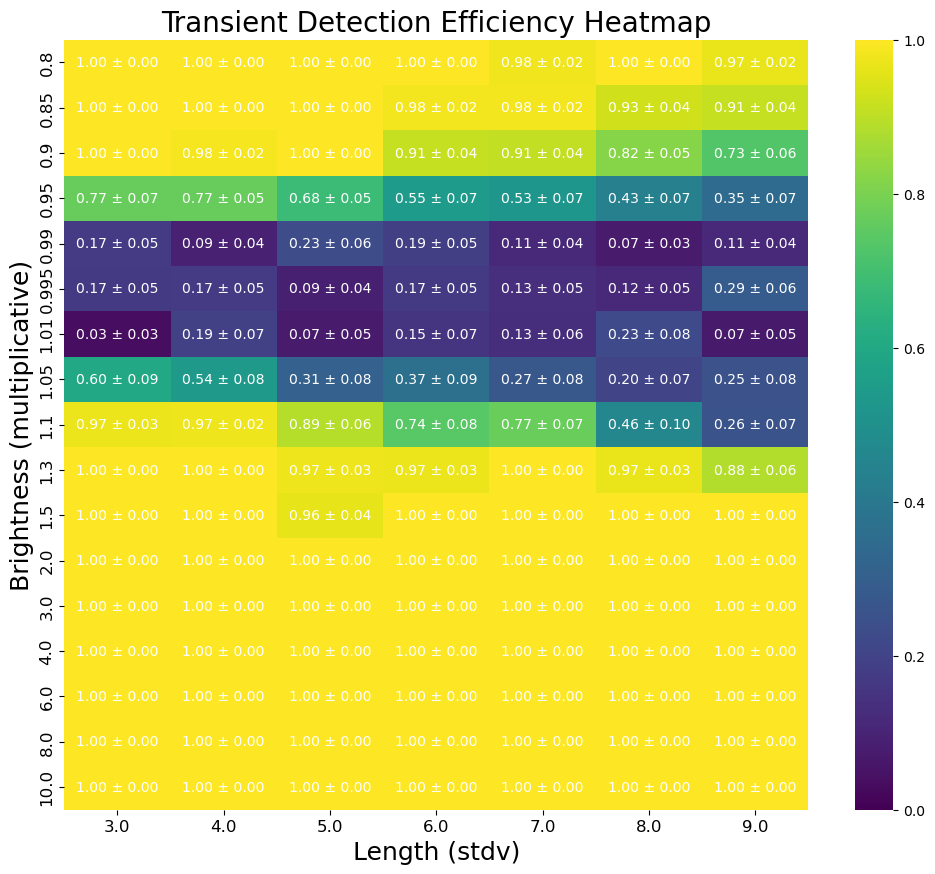

In [50]:
# Given nonlinear brightness values
brightness_values = np.unique(our_bness_te)
length_values = np.unique(our_lens_te)

# # Given nonlinear brightness and length values
# brightness_values = np.array([0.8, 0.9, 0.99, 1.01, 1.1, 2, 5, 10])
# length_values = np.array([1, 2, 3, 4, 5, 6, 7, 8])  # Example length values

# Create bins for brightness and length
brightness_bins = np.concatenate(
    [
        [brightness_values[0] - 0.1],
        (brightness_values[:-1] + brightness_values[1:]) / 2,
        [brightness_values[-1] + 0.1],
    ]
)

length_bins = np.concatenate(
    [
        [length_values[0] - 0.5],
        (length_values[:-1] + length_values[1:]) / 2,
        [length_values[-1] + 0.5],
    ]
)

# Example data: Replace these with your actual data
correct_detections = trues  # Array of correctly detected (brightness, length)
incorrect_detections = fails  # Array of incorrectly detected (brightness, length)

# Create 2D histogram for correct and total detections
correct_hist, xedges, yedges = np.histogram2d(
    correct_detections[:, 0],
    correct_detections[:, 1],
    bins=[brightness_bins, length_bins],
)

total_hist, _, _ = np.histogram2d(
    np.vstack((correct_detections, incorrect_detections))[:, 0],
    np.vstack((correct_detections, incorrect_detections))[:, 1],
    bins=[brightness_bins, length_bins],
)

# Calculate efficiency
efficiency = correct_hist / total_hist

# Calculate error (using Poisson approximation)
error = np.sqrt(efficiency * (1 - efficiency) / total_hist)

# Plotting the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    efficiency,
    xticklabels=length_values,
    yticklabels=brightness_values,
    cmap="viridis",
    annot=False,
    vmin=0,
    vmax=1,
)

# Setting the axis titles and plot title with larger font sizes
plt.xlabel("Length (stdv)", fontsize=18)
plt.ylabel("Brightness (multiplicative)", fontsize=18)
plt.title("Transient Detection Efficiency Heatmap", fontsize=20)

# Customizing tick positions and labels
plt.yticks(
    ticks=np.arange(len(brightness_values)) + 0.5, labels=brightness_values, fontsize=12
)
plt.xticks(ticks=np.arange(len(length_values)) + 0.5, labels=length_values, fontsize=12)

# Overlaying error bars and adding text annotations
for i in range(efficiency.shape[0]):
    for j in range(efficiency.shape[1]):
        if total_hist[i, j] > 0:  # Only annotate if there are detections
            # Format the annotation text
            text = f"{efficiency[i, j]:.2f} ± {error[i, j]:.2f}"
            # Add the text annotation in the center of each bin
            plt.text(
                j + 0.5,
                i + 0.5,
                text,
                ha="center",
                va="center",
                color="white",
                fontsize=10,
            )

plt.show()

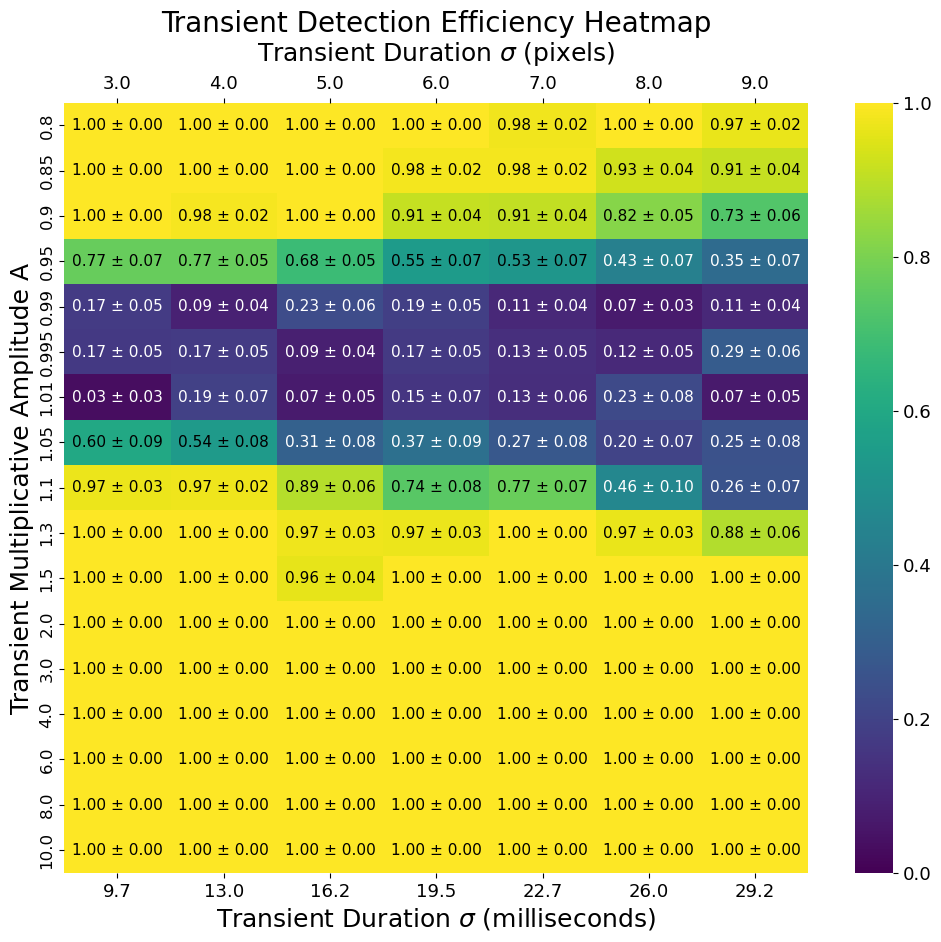

In [58]:
# Plotting the heatmap
plt.figure(figsize=(12, 10))
bottom_ticks_values = (
    np.arange(3, len(length_values) + 3) * 10000 / 3080
)  # * (10/6.15)  # Example: double the length values
bottom_tick_labels = [f"{val:.1f}" for val in bottom_ticks_values]
heatmap = sns.heatmap(
    efficiency,
    xticklabels=bottom_tick_labels,
    yticklabels=brightness_values,
    cmap="viridis",
    annot=False,
    vmin=0,
    vmax=1,
)

# Setting the bottom axis label
ax = plt.gca()  # Get the current axis
ax.set_xlabel("Transient Duration $\sigma$ (milliseconds)", fontsize=18)  # Bottom label
ax.xaxis.set_label_position("bottom")  # Ensure the label is positioned at the bottom
ax.xaxis.tick_bottom()  # Ensure the ticks are at the bottom

# Customizing the bottom ticks
# plt.xticks(ticks=bottom_ticks_values, labels=bottom_tick_labels, fontsize=12)
plt.xticks(fontsize=12)

# Creating custom ticks and label for the top axis with different numbers
top_tick_labels = length_values
ax_top = ax.twiny()  # Create a new axis sharing the x-axis
ax_top.set_xlim(ax.get_xlim())  # Ensure the limits are shared
ax_top.set_xticks(np.arange(len(length_values)) + 0.5)  # Set tick positions for top
ax_top.set_xticklabels(top_tick_labels, fontsize=13)  # Set custom labels for top
ax_top.set_xlabel(
    "Transient Duration $\sigma$ (pixels)", fontsize=18, labelpad=10
)  # Top label

# Setting y-axis label and title
ax.set_ylabel("Transient Multiplicative Amplitude A", fontsize=18)
plt.title("Transient Detection Efficiency Heatmap", fontsize=20)

# Customizing tick positions and labels for the y-axis
plt.yticks(
    ticks=np.arange(len(brightness_values)) + 0.5, labels=brightness_values, fontsize=12
)

# Overlaying error bars and adding text annotations
for i in range(efficiency.shape[0]):
    for j in range(efficiency.shape[1]):
        if total_hist[i, j] > 0:  # Only annotate if there are detections
            # Format the annotation text
            text = f"{efficiency[i, j]:.2f} ± {error[i, j]:.2f}"
            # Add the text annotation in the center of each bin
            if efficiency[i, j]<.5:
                color="white"
            else:
                color='black'
            plt.text(
                j + 0.5,
                i + 0.5,
                text,
                ha="center",
                va="center",
                color=color,
                fontsize=11,
            )

            # Remove the black outline (spines) from all sides
for spine in ax.spines.values():
    spine.set_visible(False)

for spine in ax_top.spines.values():
    spine.set_visible(False)


# Adjust tick label size
ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=13)


# Access the colorbar and modify tick font size
cbar = heatmap.collections[0].colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=13)  # Adjust tick label size


plt.show()

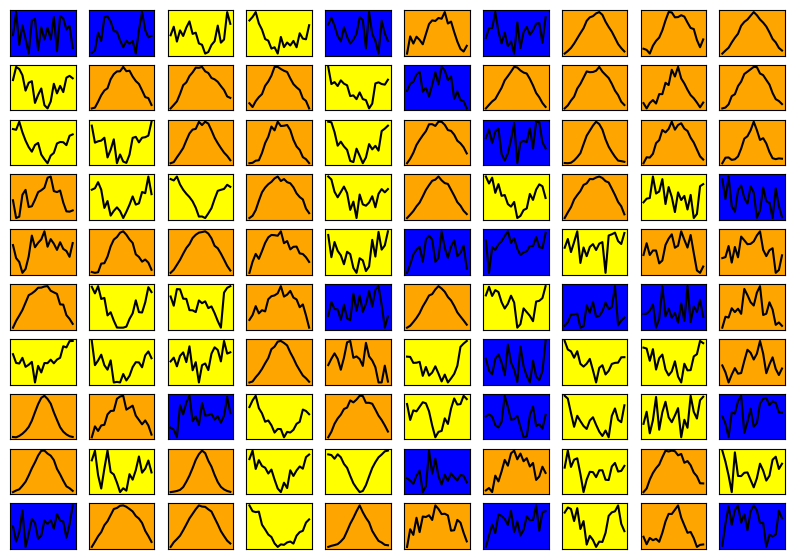

In [78]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].set_facecolor(colors[our_pred_te_max[i * 10 + h]])
        # ax[i, h].axis("off")
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

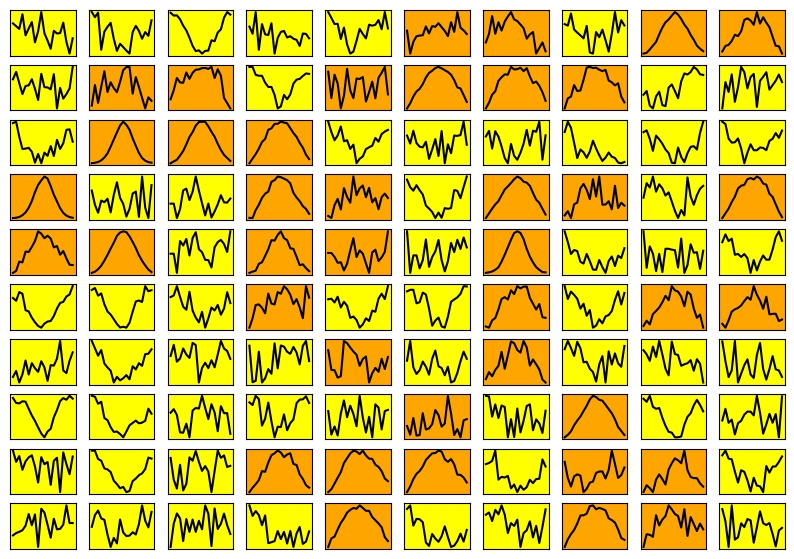

In [250]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].set_facecolor(colors[our_targ_te[i * 10 + h]])
        # ax[i, h].axis("off")
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

In [89]:
our_feat_te_info[0, 0]

0.99

In [178]:
colors2 = [0, 1, 2, "red", "orange", "yellow", "green", "blue", "purple", "violet"]

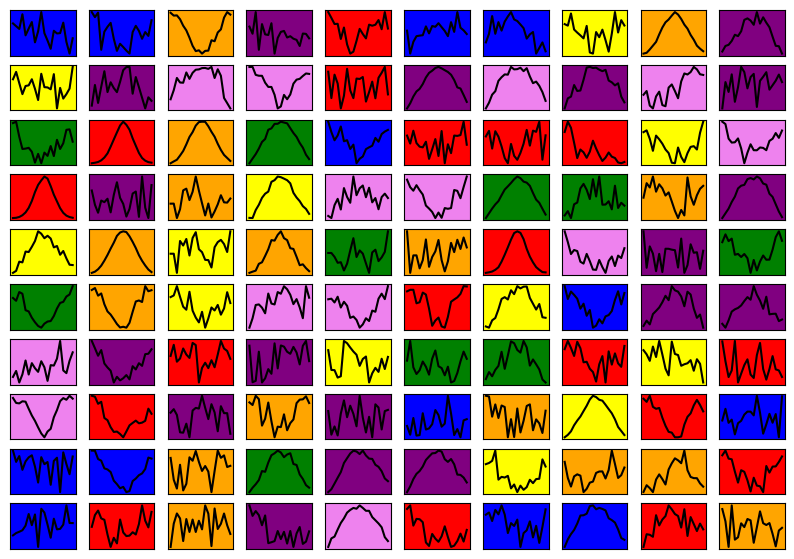

In [251]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info[i*10 + h,1]/10, .5, .5))
        ax[i, h].set_facecolor(colors2[int(our_feat_te_info[i * 10 + h, 1])])
        # ax[i, h].axis("off")
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

In [ ]:
# i'm not convinced the lengths are working right
# ...eh maybe they are. purple/pink should be

In [124]:
x = np.linspace(0.0, 1.0, 1001)
rgb = mpl.colormaps["viridis"](x)[np.newaxis, :, :3]

In [107]:
np.max(100 * (our_feat_te_info[:, 0]))

1000.0

In [120]:
np.shape(rgb)

(1, 1000, 3)

In [113]:
rgb[int(100 * (our_feat_te_info[i * 10 + h, 0]))]

IndexError: index 99 is out of bounds for axis 0 with size 1

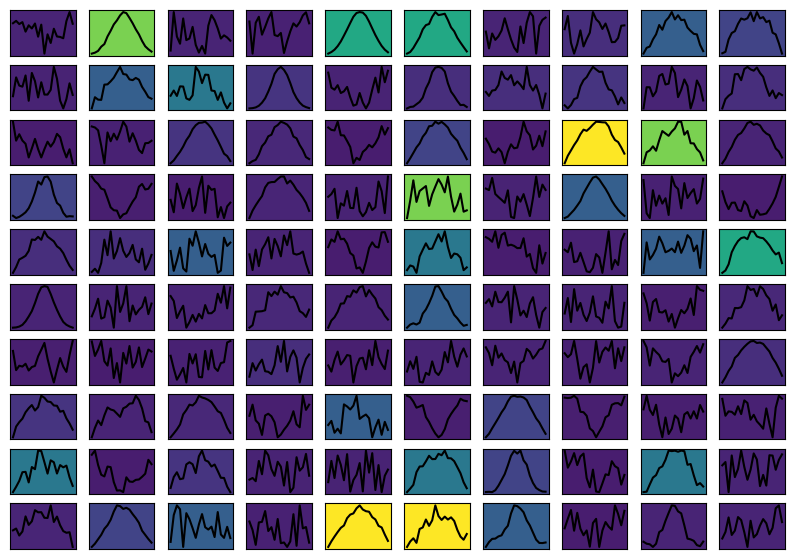

In [125]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info[i*10 + h,1]/10, .5, .5))
        ax[i, h].set_facecolor(rgb[0, int(100 * (our_feat_te_info[i * 10 + h, 0]))])
        # ax[i, h].axis("off")
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

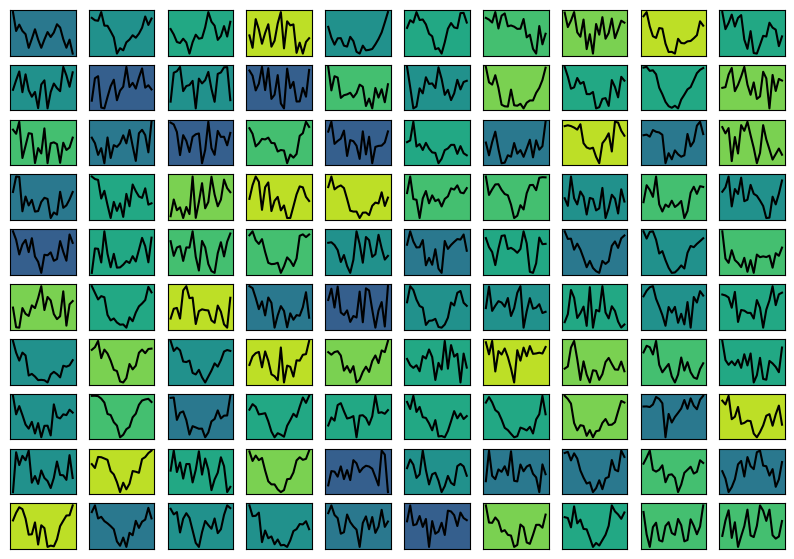

In [148]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te_p8[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info_p8[i*10 + h,1]/10, .5, .5))
        ax[i, h].set_facecolor(rgb[0, int(100 * (our_feat_te_info_p8[i * 10 + h, 1]))])
        # ax[i, h].axis("off")
        # ax[i, h].set_facecolor(colors[our_label_pred_te_max_p8[i*10 + h]])
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

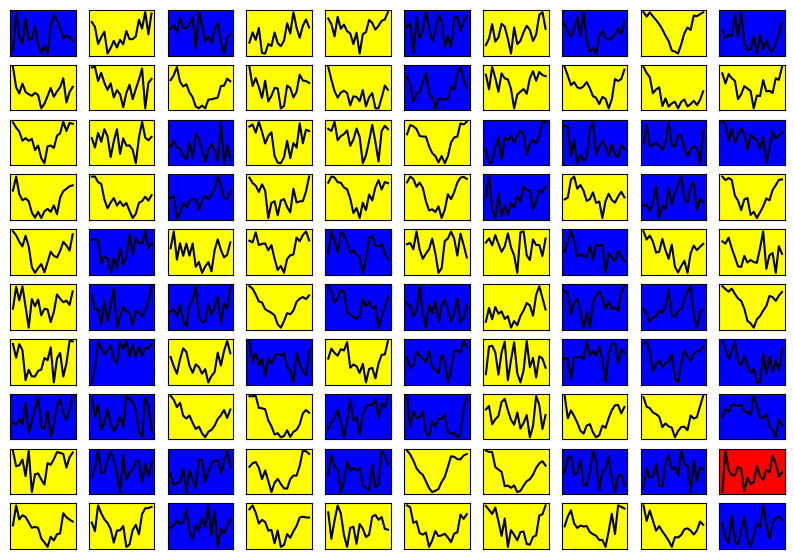

In [40]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.mean(our_feat_te_995[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info_p8[i*10 + h,1]/10, .5, .5))
        # ax[i, h].set_facecolor(rgb[0,int(100*(our_feat_te_info_p8[i*10 + h,1]))])
        # ax[i, h].axis("off")
        ax[i, h].set_facecolor(colors[our_label_pred_te_max_995[i * 10 + h]])
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

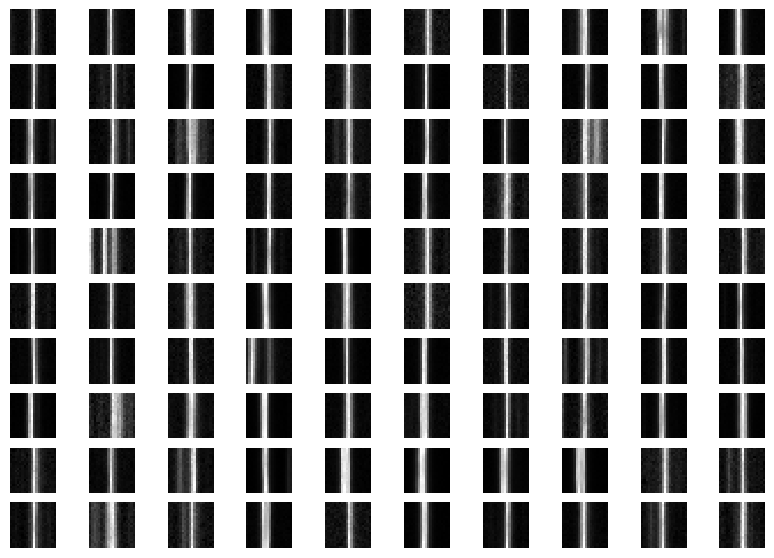

In [36]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        # ax[i, h].plot(np.sum(our_feat_te_995[i*10 + h], axis=1), "black")
        ax[i, h].imshow(our_feat_te_995[i * 10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info_p8[i*10 + h,1]/10, .5, .5))
        # ax[i, h].set_facecolor(rgb[0,int(100*(our_feat_te_info_p8[i*10 + h,1]))])
        ax[i, h].axis("off")
        # ax[i, h].set_facecolor(colors[our_label_pred_te_max_995[i*10 + h]])
        # ax[i, h].set_xticks([])
        # ax[i, h].set_yticks([])
fig.show()

In [41]:
feat_te_info[:, 0]

array([0.99, 0.  , 0.  , ..., 4.  , 0.  , 0.  ])

In [45]:
unique, counts = np.unique(feat_te_info[:, 0], return_counts=True)

In [ ]:
unique

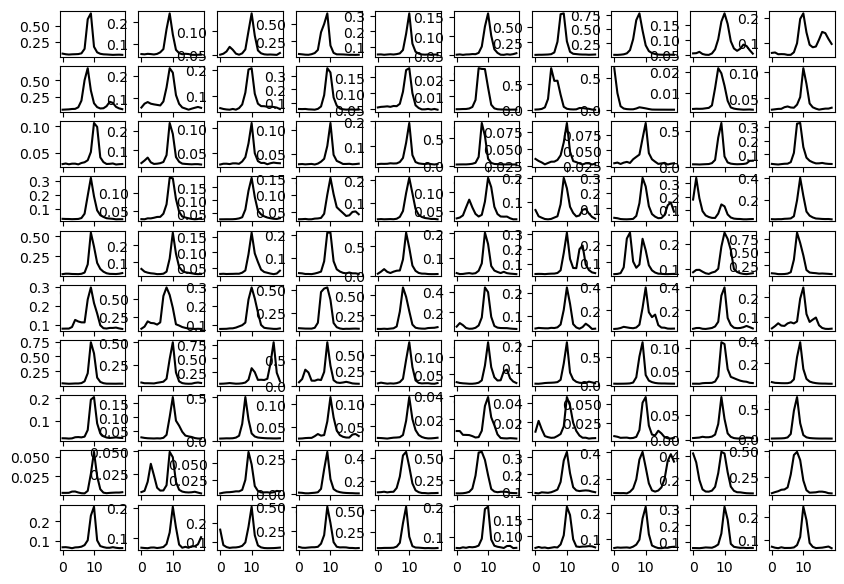

In [74]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.mean(all_streak_stamps[i * 10 + h], axis=0), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info_p8[i*10 + h,1]/10, .5, .5))
        # ax[i, h].set_facecolor(rgb[0,int(100*(our_feat_te_info_p8[i*10 + h,1]))])
        # ax[i, h].axis("off")
        # ax[i, h].set_facecolor(colors[our_label_pred_te_max_995[i*10 + h]])
        # ax[i, h].set_xticks([])
        # ax[i, h].set_yticks([])
fig.show()

[4, 4]


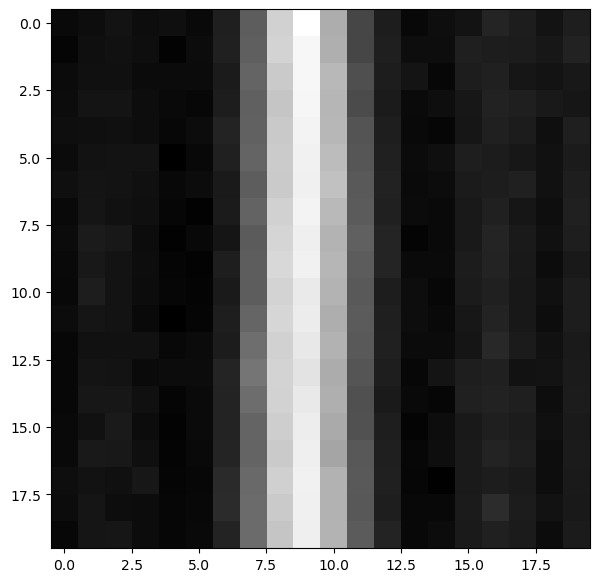

stamp info:  (0.99, 3)
[4, 4]


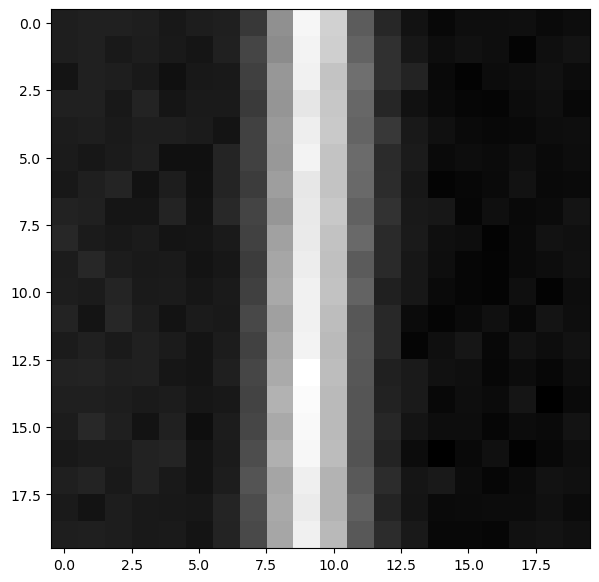

stamp info:  (0.99, 3)
[5, 5]


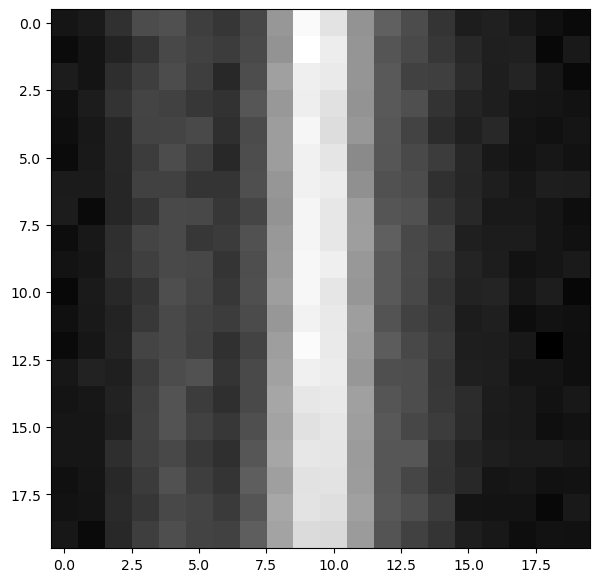

stamp info:  (0.99, 3)
[4, 4]


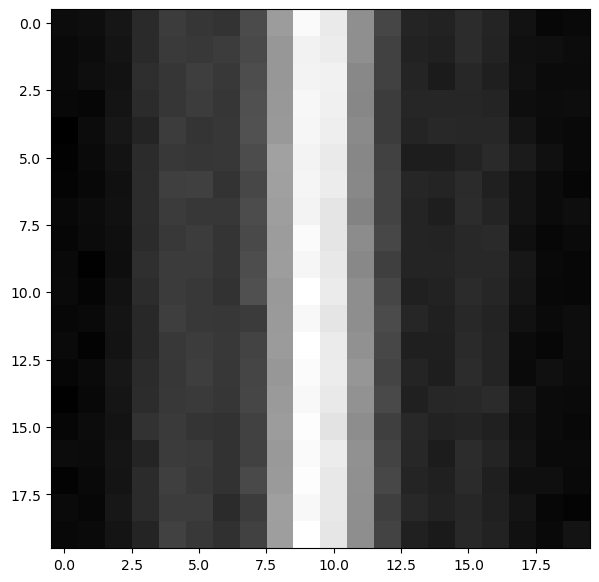

stamp info:  (0.99, 3)
[5, 5]


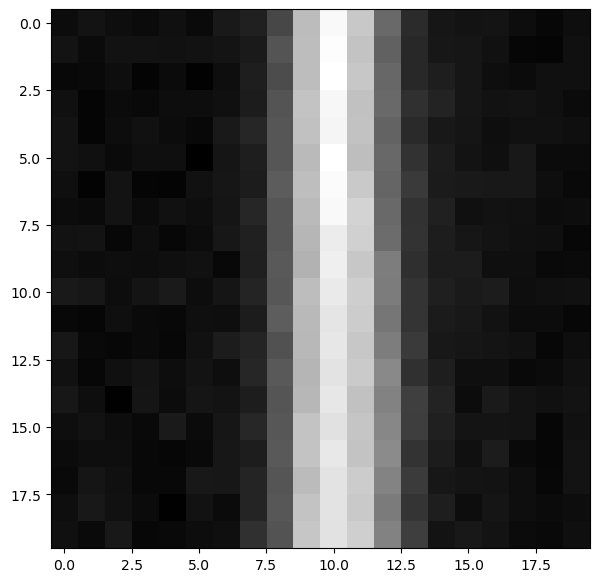

stamp info:  (0.99, 3)
[5, 5]


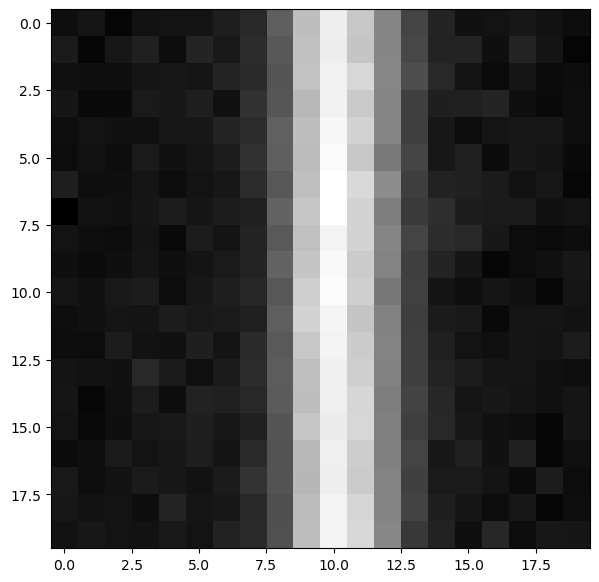

stamp info:  (0.99, 3)
[4, 4]


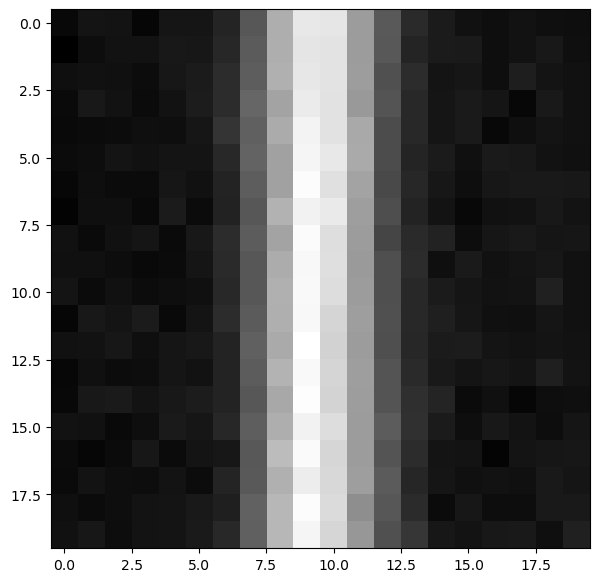

stamp info:  (0.99, 3)
[3, 3]


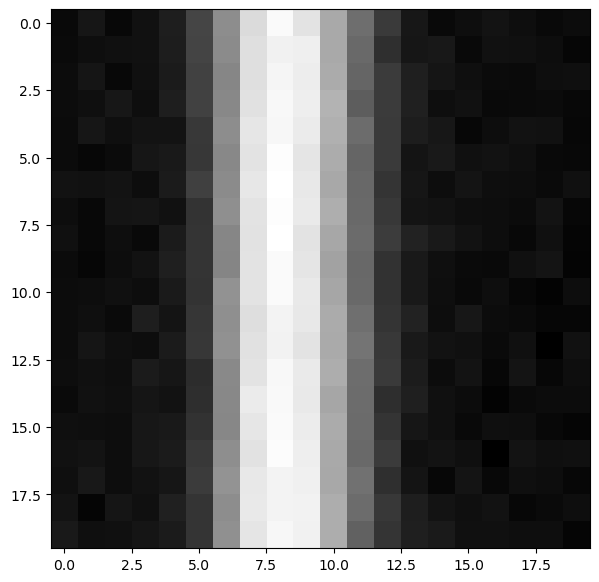

stamp info:  (0.99, 3)


In [139]:
np.shape(all_pos_stamps_15)

(895, 2)

In [157]:
np.unique(all_pos_stamps_info[: len(all_pos_stamps), 0])

array([ 1.01,  1.05,  1.1 ,  1.3 ,  1.5 ,  2.  ,  3.  ,  4.  ,  6.  ,
        8.  , 10.  ])

In [ ]:
our_feat_te_p8 = our_feat_te[our_outs_te == 0.8]

In [67]:
def save_predsarrays(image, model, wid, path):
    """
    This function will take an image and a cnn model and return an array
    of the transients found in that image.
    image: np array
    model: cnn model
    abst_thr: absolute probability threshold to consider a transient probability as a transient
    mult_thr: comparative probability threshold to consider a transient probability as a transient
    (aka the trans prob has to be x times larger than (streak prob + backg prob)
    wid: desired postage stamp width
    bg_thresh: thresh to consider the average background on a column to be "background",
    something like .1, used as criterion for determining cosmic rays
    path: path to save the array

    returns (and saves): array of length (number of transient detections),
    with elements of (detection row, detection column), transient detection size,
    realness (aka not-cosmic-ray)
    so a list of tuples, then an int, then the probability that its column is a streak
    to flag as a probable cosmic ray
    """

    nrow, ncol = image.shape
    print("getting postage stamps")
    stamps = gpsf.get_postage_stamps_full(image, 10)
    stampbatches = np.array_split(
        stamps, stamps.shape[0] // 20000
    )  # (image.shape[0] - 2 * wid) )
    # I WANNA CHANGE THIS TO SPEED HIM UP
    # so to be faster there should be less batches
    # so i want the second argument to be smaller
    # so i want the denomitor of the second argument to be larger
    preds = []
    print("getting predictions:")
    for stamps in tqdm(
        stampbatches
    ):  # getting all the predictions. does not renormalize
        pred_l = model.predict_on_batch(stamps)
        preds.append(pred_l)
    predsarray = np.concatenate(preds)
    # i would like to save the predsarrays i think. for reproducibility
    # np.save(path+"_predsarray", predsarray) #TURN THIS BACK ON LATER
    del stamps
    del stampbatches
    del preds
    gc.collect()
    return predsarray

In [68]:
predsarray1 = save_predsarrays(testimp, model, wid, path=None)

getting postage stamps
getting stamps now


  0%|          | 0/3052 [00:00<?, ?it/s]

getting predictions:


  0%|          | 0/466 [00:00<?, ?it/s]

2024-11-11 12:54:27.888867: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype float and shape [20042,20,20]
	 [[{{node Placeholder/_0}}]]
2024-11-11 12:54:29.937725: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype float and shape [20042,20,20]
	 [[{{node Placeholder/_0}}]]
2024-11-11 12:54:30.050947: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype float and 

In [7]:
testimp = np.load(
    "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/images/ztf_20221014279051_000501_zr_c16_x_0025._implanted10.npy"
)

In [5]:
import get_postage_stamps as gpsf
import gc  # garbage collector
import precision_recall as pr

In [6]:
pray = np.load(
    "/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020297847_000449_zr_c16_x_0022._extraction_predsarray_4_predsarray.npy"
)

In [17]:
np.shape(pray)

(9339120, 5)

In [9]:
wid = 10
nrow, ncol = testimp.shape
pimg_pos = pray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_bg = pray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_streak = pray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_neg = pray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_cr = pray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)

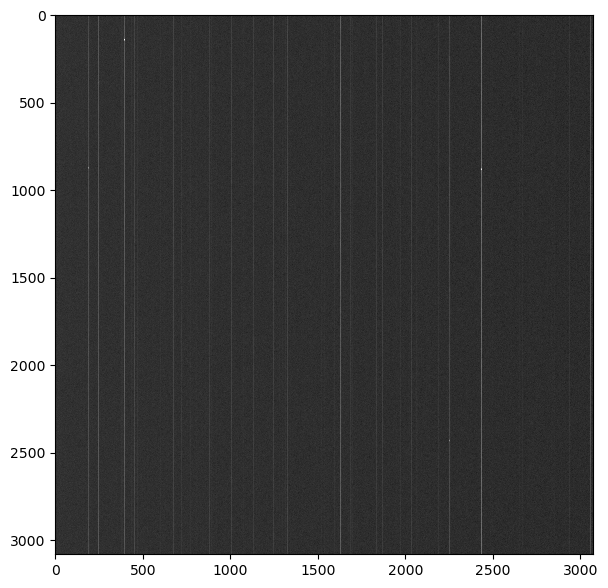

In [10]:
plt.imshow(np.sqrt(testimp))

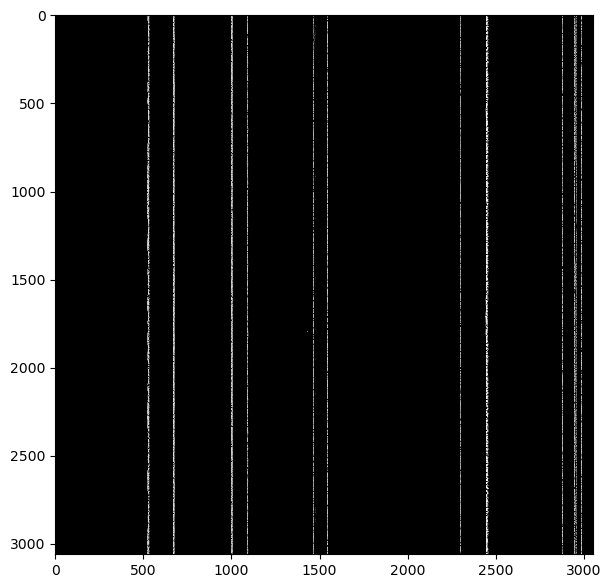

In [30]:
plt.imshow(pimg_streak.T)

In [34]:
def make_obj_list(image, predsarray, abst_thr, fname):
    wid = 10
    nrow, ncol = image.shape
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)

    pimg_both = pimg_pos + pimg_neg

    structure = [[1, 1, 1], [1, 1, 1], [1, 1, 1]]  # for what counts as one object

    # FOR POS
    thrdet = pimg_pos > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_pos = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_pos = np.array(loc_list_pos)
    objsizes_pos = pr.get_objsizes(labs, nlabs)

    # brightnesses = np.zeros(len(loc_list))
    # # bg_thresh=.1
    # cosmicray = []
    # rows = np.zeros(len(loc_list))
    # cols = np.zeros(len(loc_list))
    # for k, loc in enumerate(loc_list):
    #     (row, col) = loc
    #     rows[k] = int(row)
    #     cols[k] = int(col)
    #     # print("loc = row,col= "+str(loc))
    #     # print(row)
    #     # print(col)
    #     colavg = np.average(pimg_bg.T[:,int(col)]) #not actually the column average
    #     #print("colavg: "+str(colavg) )
    #     # if colavg>bg_thresh: #column is mostly not background - can adjust this cutoff
    #     cosmicray.append(colavg)
    #     brightnesses[k] = image[int(row)+wid, int(col)+wid]

    fnames = np.full(len(loc_list_pos), fname)
    poses = np.full(len(loc_list_pos), "pos")
    poslist = (
        np.vstack((fnames, poses, loc_list_pos[:, 0], loc_list_pos[:, 1], objsizes_pos))
    ).T

    # FOR NEG
    thrdet = pimg_neg > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_neg = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_neg = np.array(loc_list_neg)

    objsizes_neg = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_neg), fname)
    negs = np.full(len(loc_list_neg), "neg")
    neglist = (
        np.vstack((fnames, negs, loc_list_neg[:, 0], loc_list_neg[:, 1], objsizes_neg))
    ).T

    # FOR CRS
    thrdet = pimg_cr > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_cr = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_cr = np.array(loc_list_cr)

    objsizes_cr = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_cr), fname)
    crs = np.full(len(loc_list_cr), "cr")
    print(np.shape(fnames))
    print(np.shape(crs))
    print(np.shape(loc_list_cr[:, 0]))
    print(np.shape(loc_list_cr[:, 1]))
    print(np.shape(objsizes_cr))
    crlist = (
        np.vstack((fnames, crs, loc_list_cr[:, 0], loc_list_cr[:, 1], objsizes_cr))
    ).T

    # FOR BOTH
    thrdet = pimg_both > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_both = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_both = np.array(loc_list_both)

    objsizes_both = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_both), fname)
    boths = np.full(len(loc_list_both), "both")
    bothlist = (
        np.vstack(
            (fnames, boths, loc_list_both[:, 0], loc_list_both[:, 1], objsizes_both)
        )
    ).T

    del pimg_cr
    del pimg_pos
    del pimg_neg
    del pimg_bg
    del pimg_streak
    del thrdet
    del loc_list_pos
    del loc_list_neg
    del objsizes_pos
    del objsizes_neg
    del labs
    del threshed
    gc.collect()

    listlist = np.vstack((poslist, neglist, crlist, bothlist))
    alllist = pd.DataFrame(listlist)

    alllist.rename(
        columns={
            0: "filename",
            1: "type",
            2: "row_from_nn",
            3: "col_from_nn",
            4: "detection_size",
        },
        inplace=True,
    )

    alllist[["row_from_nn", "col_from_nn", "detection_size"]] = alllist[
        ["row_from_nn", "col_from_nn", "detection_size"]
    ].apply(pd.to_numeric)
    # np.save(path, n_loc_size_ray_b)
    return poslist, neglist, crlist, bothlist, alllist

In [4]:
import pandas as pd

In [35]:
poslist, neglist, crlist, bothlist, alllist = make_obj_list(
    testimp, pray, 0.9999, "fname"
)

(15,)
(15,)
(15,)
(15,)
(15,)


In [36]:
alllist["detection_size"] > 15

0      False
1      False
2      False
3      False
4      False
       ...  
317    False
318    False
319    False
320    False
321    False
Name: detection_size, Length: 322, dtype: bool

In [37]:
alllist[alllist["detection_size"] > 15]

,filename,type,row_from_nn,col_from_nn,detection_size
22,fname,pos,1801.414634,1425.243902,41
23,fname,pos,1805.588235,1501.352941,17
39,fname,pos,2654.821429,144.000000,28
45,fname,neg,53.500000,241.000000,16
47,fname,neg,68.407407,241.296296,27
52,fname,neg,143.823529,2445.588235,17
54,fname,neg,182.181818,2445.772727,22
55,fname,neg,263.782609,2445.086957,23
69,fname,neg,589.363636,339.636364,22
112,fname,neg,1780.888889,2444.888889,18


In [28]:
alllist

,filename,type,row_from_nn,col_from_nn,detection_size
0,fname,pos,78.6923076923077,2445.6923076923076,13
1,fname,pos,121.0,2445.0,3
2,fname,pos,134.5,2445.0,4
3,fname,pos,190.75,2445.25,4
4,fname,pos,255.5,2445.0,2
...,...,...,...,...,...
317,fname,both,2831.5,2445.0,4
318,fname,both,2839.6666666666665,2445.8888888888887,9
319,fname,both,2910.0,2445.0,1
320,fname,both,2940.0,2451.0,1


In [147]:
import pandas as pd

In [268]:
df_detections_both = pd.DataFrame(bothlist)

In [269]:
df_detections_both.rename(
    columns={
        0: "filename",
        1: "type",
        2: "row_from_nn",
        3: "col_from_nn",
        4: "detection_size",
    },
    inplace=True,
)

In [270]:
df_detections_both

,filename,type,row_from_nn,col_from_nn,detection_size
0,fname,both,131.9938080495356,387.04334365325076,323
1,fname,both,121.4,396.6,5
2,fname,both,130.3,396.6,20
3,fname,both,161.5,1623.0,2
4,fname,both,170.0,1618.0,3
5,fname,both,363.4375,1825.75,16
6,fname,both,374.04545454545456,238.70454545454547,44
7,fname,both,378.6666666666667,1826.4285714285713,21
8,fname,both,383.2413793103448,238.82758620689654,29
9,fname,both,698.4,822.2,5


In [256]:
df_detections_pos

,filename,type,row_from_nn,col_from_nn,detection_size
0,fname,pos,121.4,396.6,5
1,fname,pos,130.52884615384616,387.1730769230769,104
2,fname,pos,374.04545454545456,238.70454545454547,44
3,fname,pos,862.6463414634146,181.0731707317073,82
4,fname,pos,860.5,2435.0,2
5,fname,pos,870.7142857142857,2425.704081632653,98
6,fname,pos,1876.7368421052631,0.47368421052631576,19
7,fname,pos,2067.878787878788,1318.5454545454545,33
8,fname,pos,2411.5,2251.0,2
9,fname,pos,2420.57,2241.65,100


Threshold:  0.9999


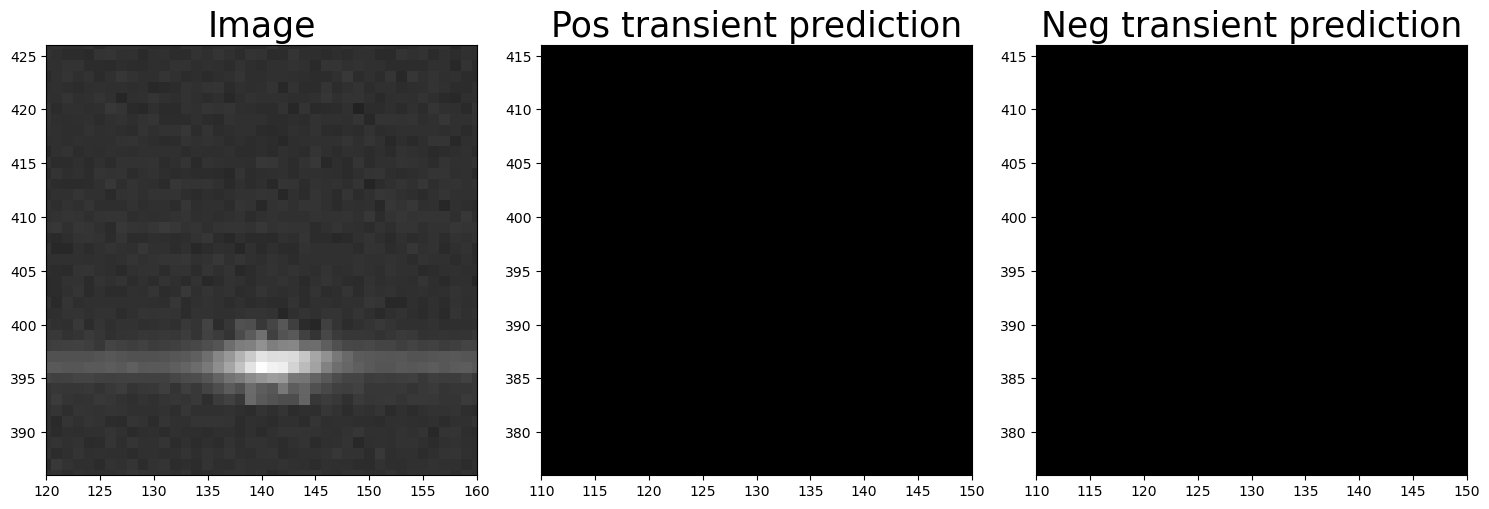

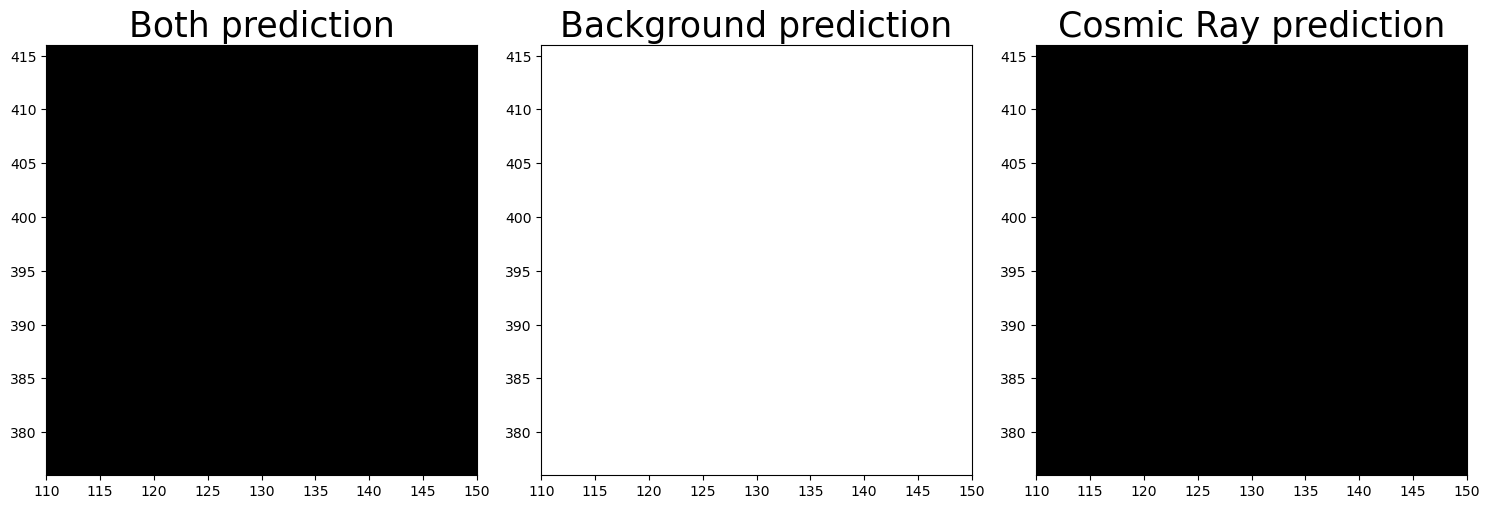

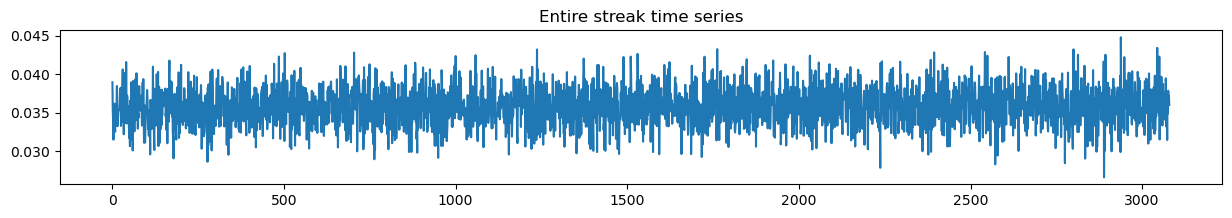

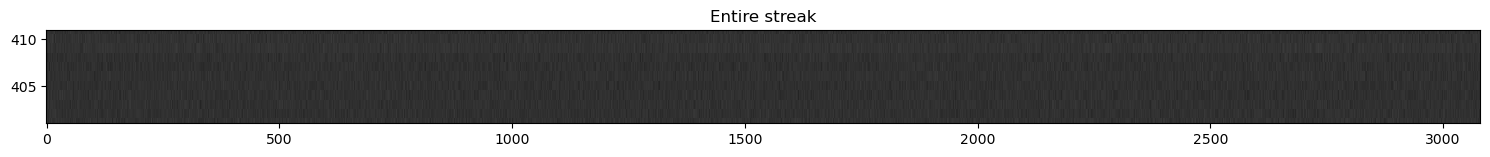

In [14]:
zoominthere2((130, 396), testimp, pray, 0.9999, 10)

Threshold:  0.9999


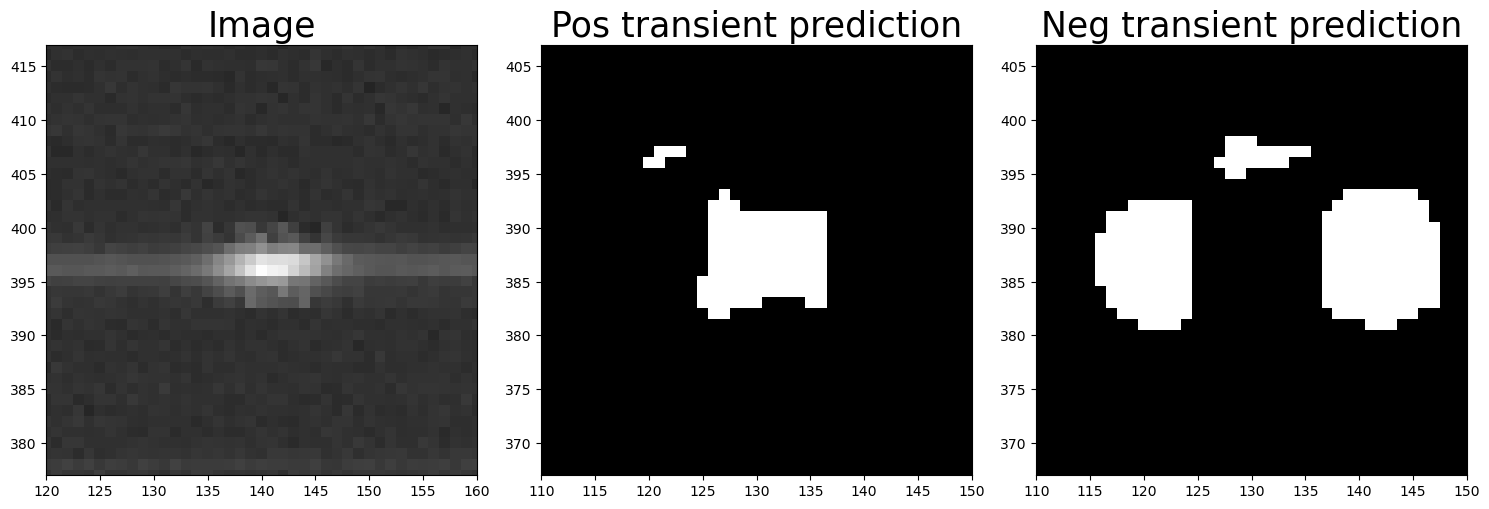

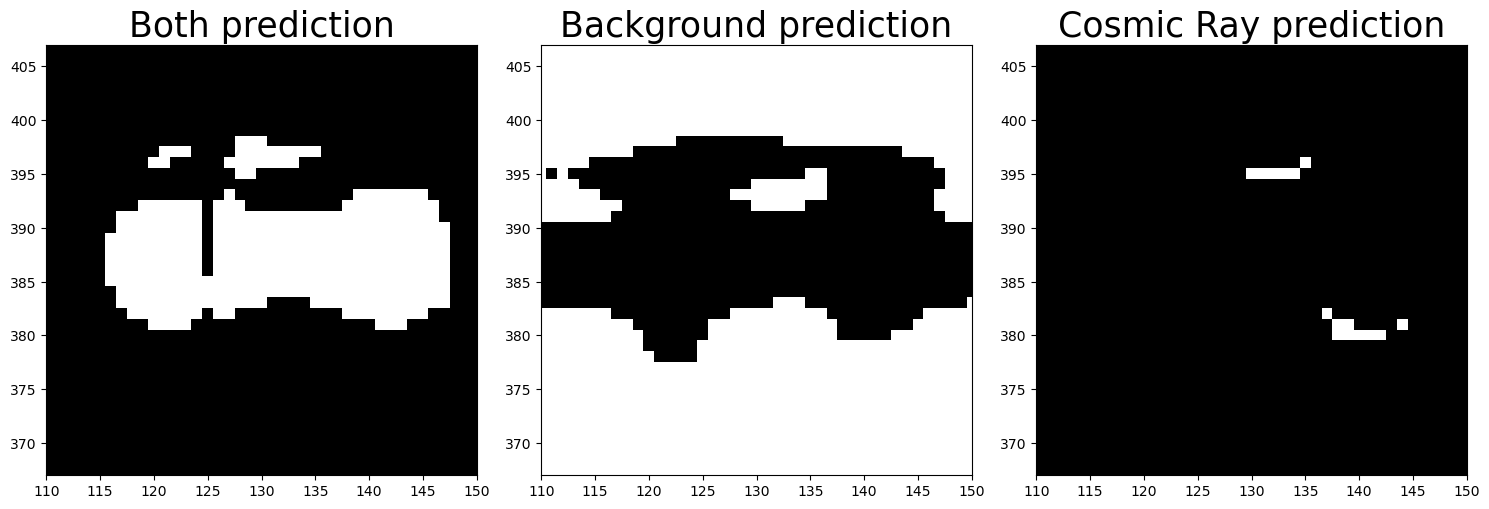

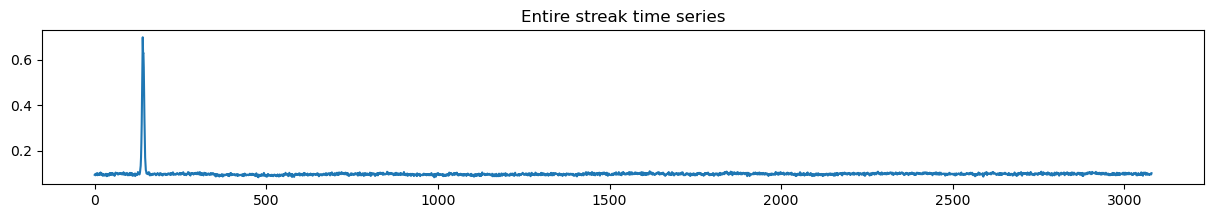

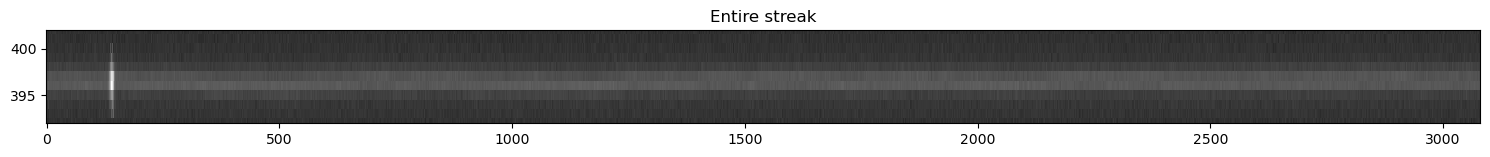

In [69]:
zoominthere2((130, 387), testimp, predsarray1, 0.9999, 10)

Threshold:  0.99


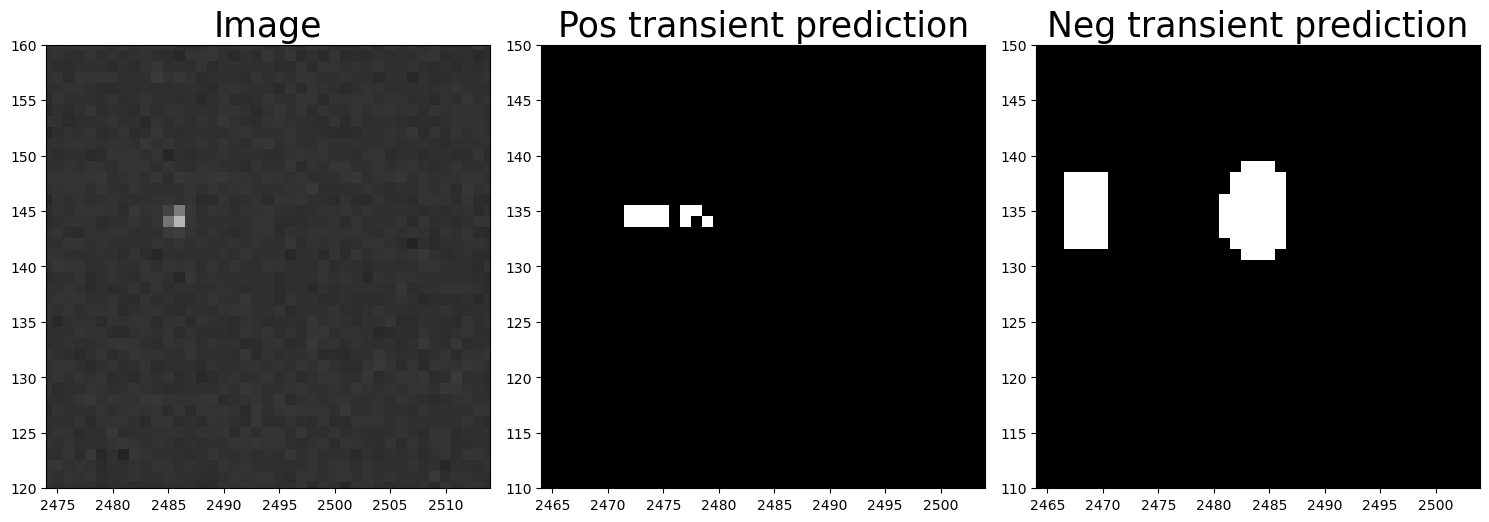

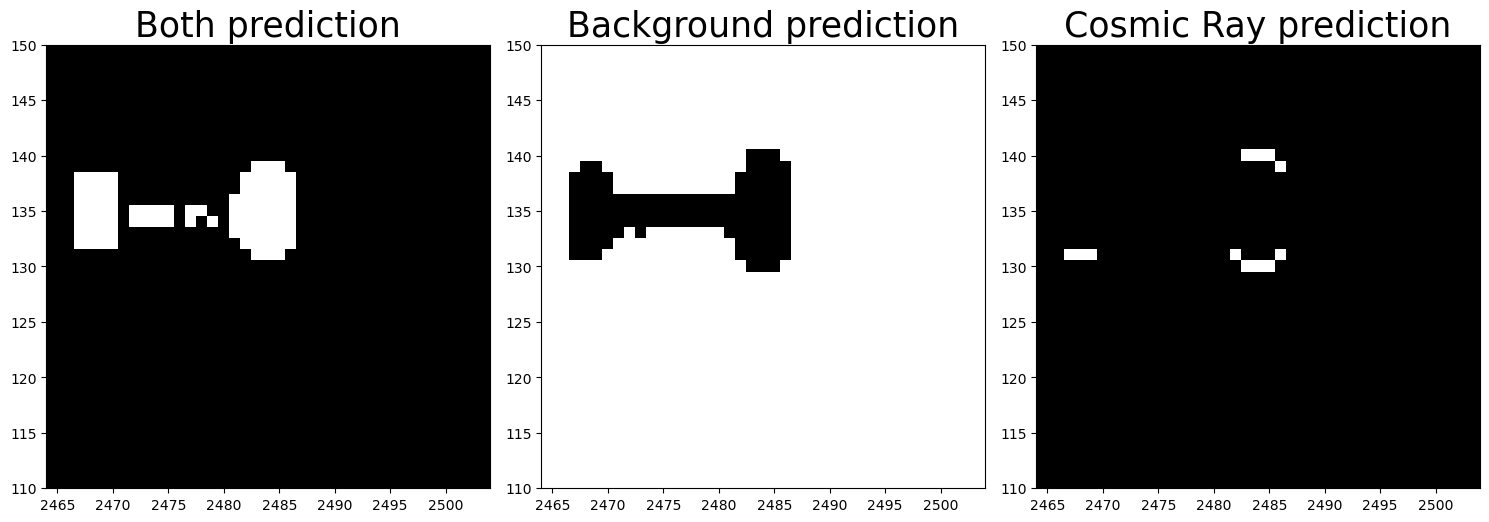

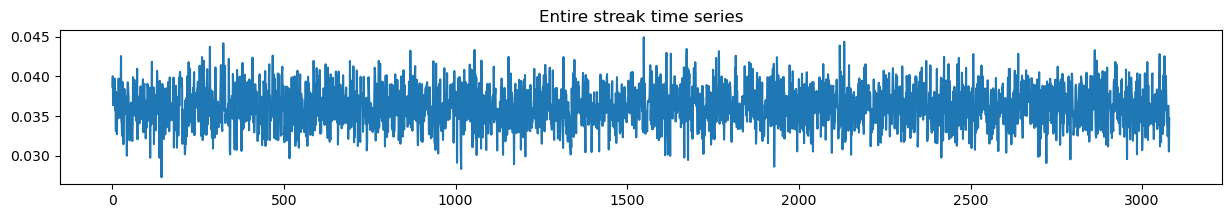

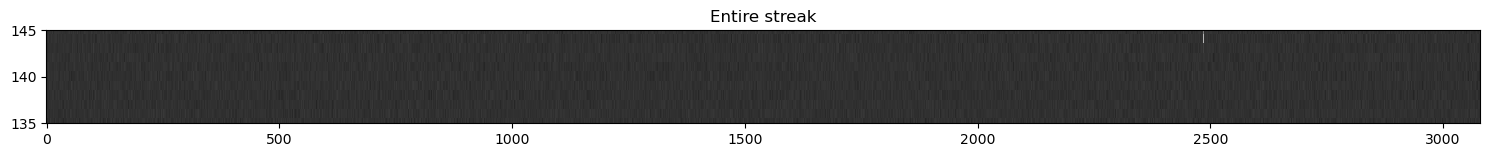

In [303]:
zoominthere2((2484, 130), testimp, pray, 0.99, 10)

Threshold:  0.5


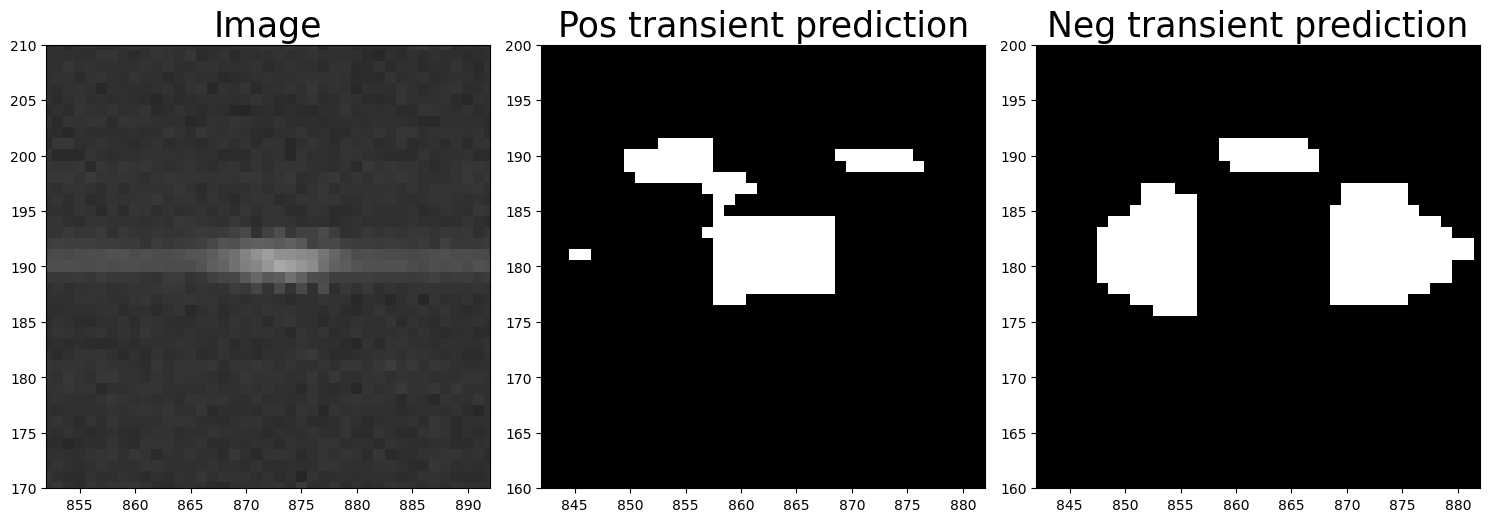

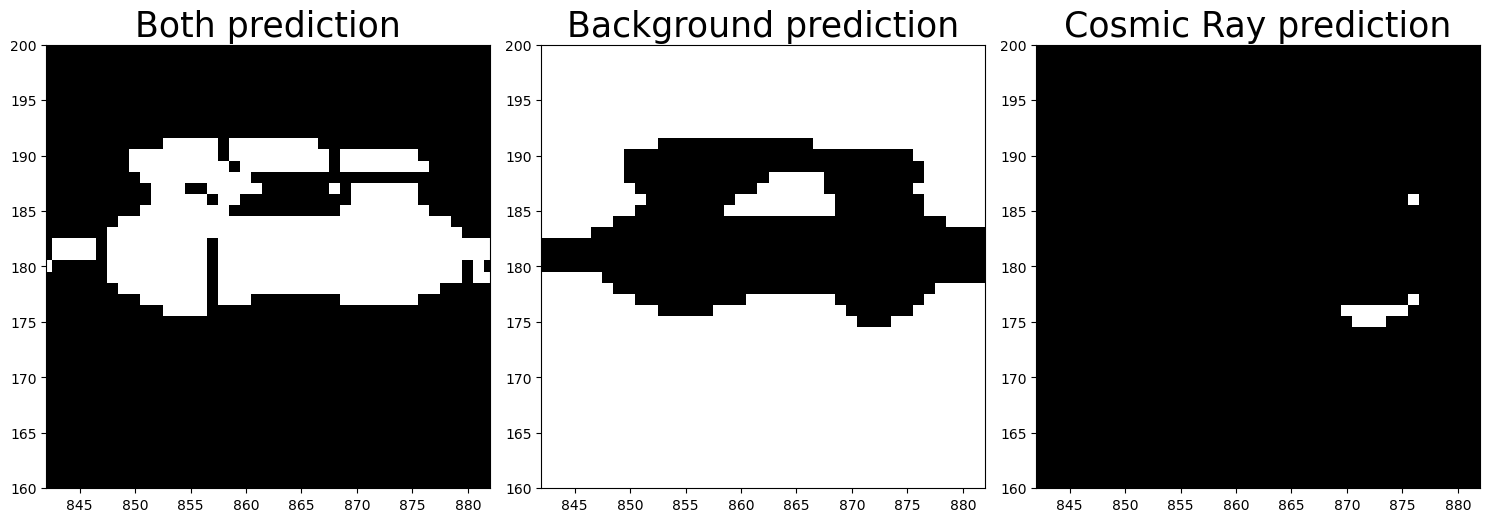

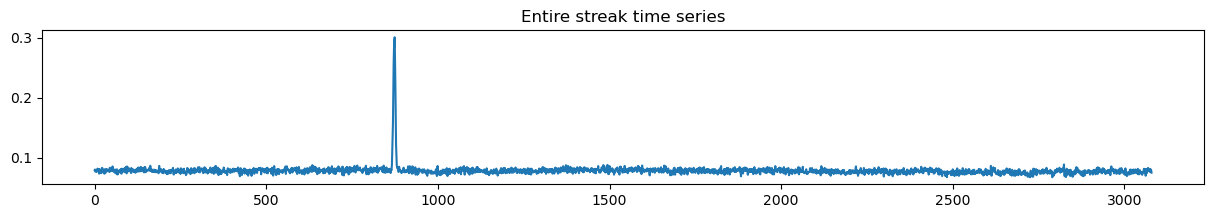

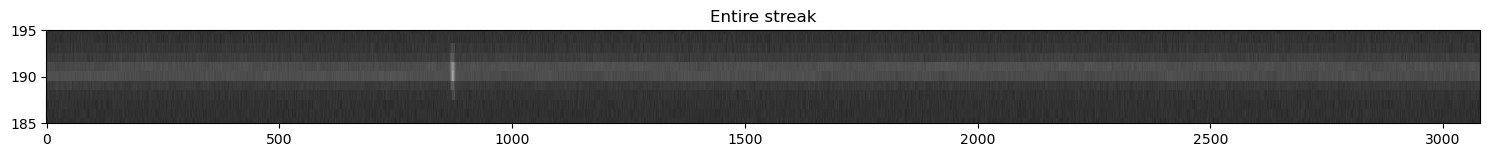

In [304]:
zoominthere2((862, 180), testimp, pray, 0.5, 10)

In [46]:
def zoominthere2(loc, image, predsarray, thr, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    nrow, ncol = image.shape
    wid = 10
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_both = pimg_pos + pimg_neg
    wid = offset
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    row, col = loc
    print("Threshold: ", thr)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image", fontsize=25)
    ax[1].imshow((pimg_pos > thr))
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Pos transient prediction", fontsize=25)
    ax[2].imshow((pimg_neg > thr))
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Neg transient prediction", fontsize=25)
    # plt.colorbar()
    # ax[1].plot((image[:,int(col+wid)]+image[:,int(col+wid)+1]+image[:,int(col+wid)-1])/3)
    # ax[1].set_xlim(row-20+wid,row+20+wid)
    # ax[1].set_title("Time series average of image row "
    #                 +str(int(col+wid))
    #                +" and adjacent")
    plt.tight_layout()
    # plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.1)
    plt.show()

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    row, col = loc
    # print(loc)
    ax[0].imshow((pimg_both > thr))
    ax[0].set_ylim(col - 20, col + 20)
    ax[0].set_xlim(row - 20, row + 20)
    ax[0].set_title("Both prediction", fontsize=25)
    # plt.colorbar()
    ax[1].imshow((pimg_bg > thr))
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Background prediction", fontsize=25)
    ax[2].imshow((pimg_cr > thr))
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Cosmic Ray prediction", fontsize=25)
    plt.tight_layout()
    # plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.1)
    plt.show()

    fig2, ax2 = plt.subplots(1, 1, figsize=(15, 2))
    ax2.plot(
        (
            image[:, int(col + wid)]
            + image[:, int(col + wid) + 1]
            + image[:, int(col + wid) - 1]
        )
        / 3
    )
    ax2.set_title("Entire streak time series")
    plt.show()
    fig3, ax3 = plt.subplots(1, 1, figsize=(15, 2))
    ax3.imshow(np.sqrt(image.T), aspect=20)
    ax3.set_ylim(col + wid - 5, col + wid + 5)
    ax3.set_title("Entire streak")
    plt.tight_layout()
    plt.show()

Threshold:  0.9999


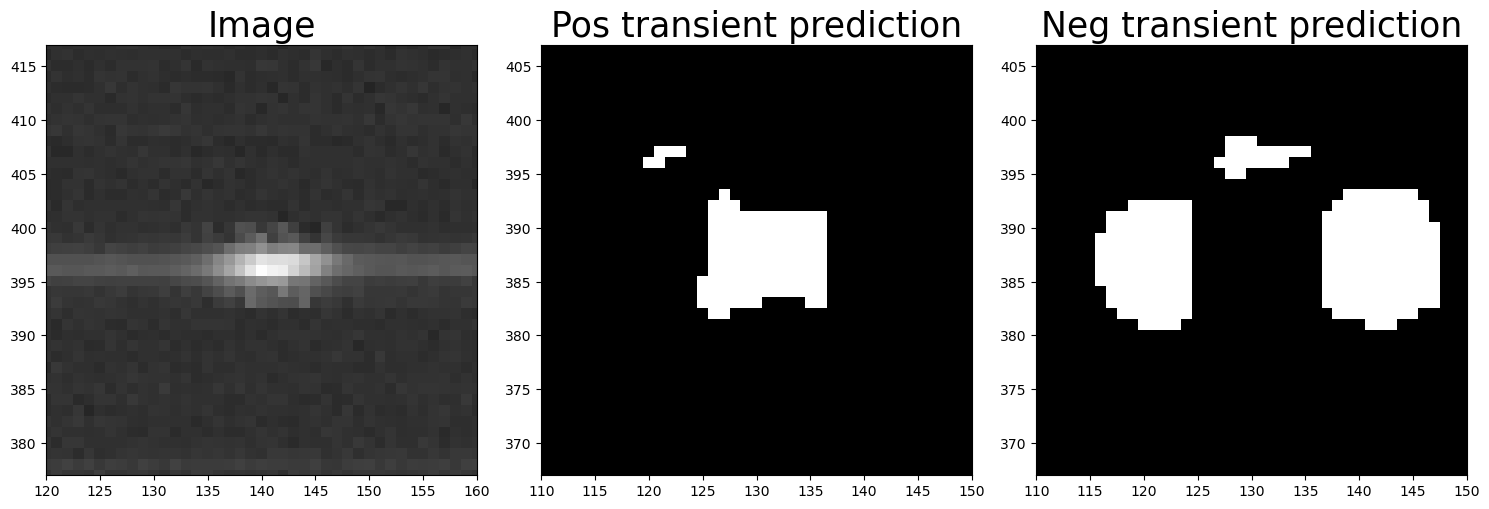

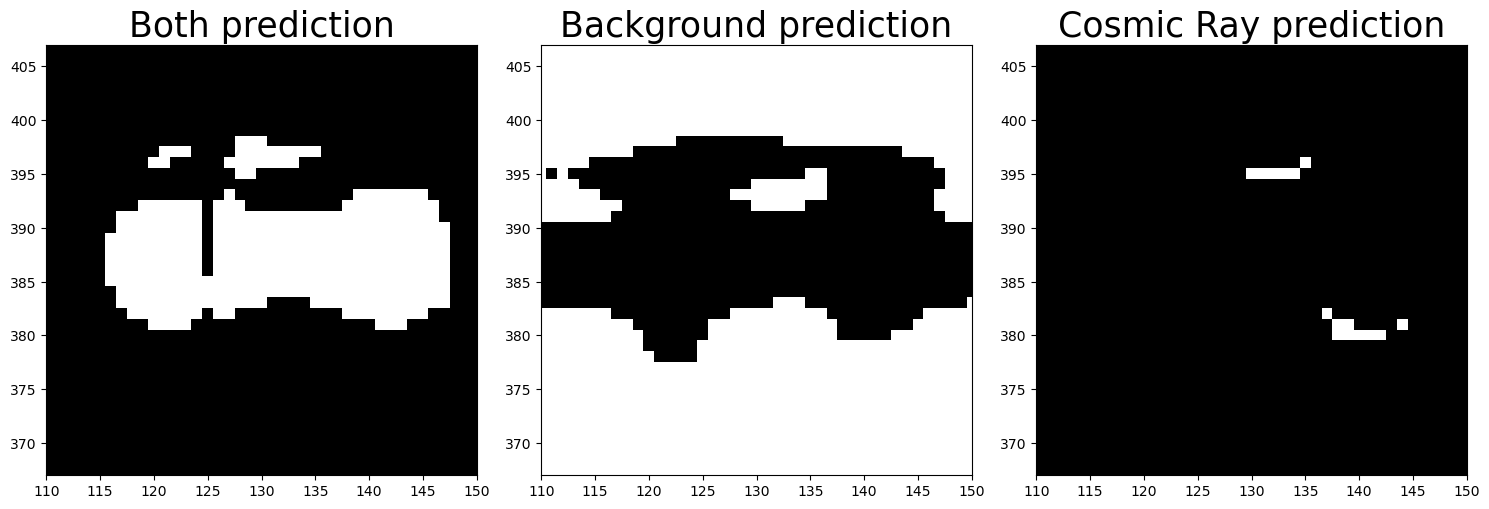

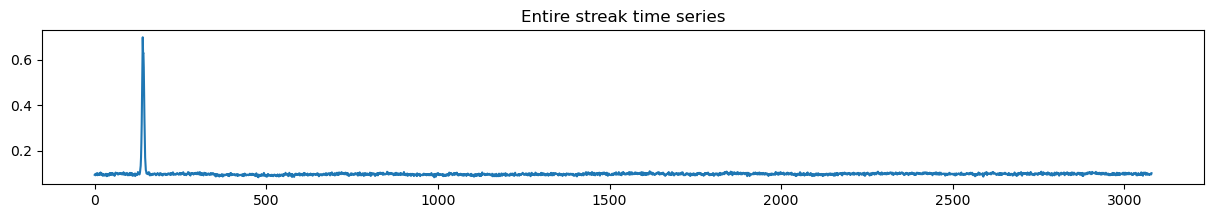

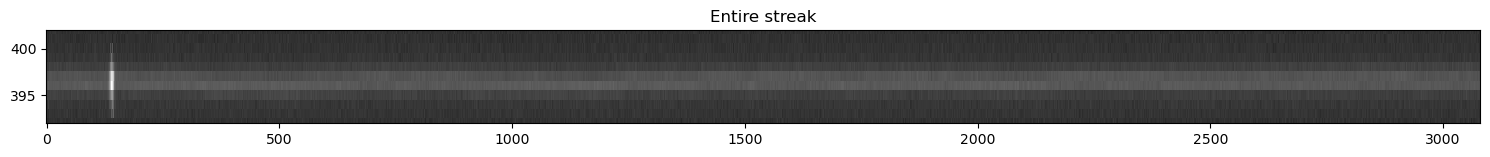

In [71]:
zoominthere2((130, 387), testimp, predsarray1, 0.9999, 10)

Threshold:  0.5


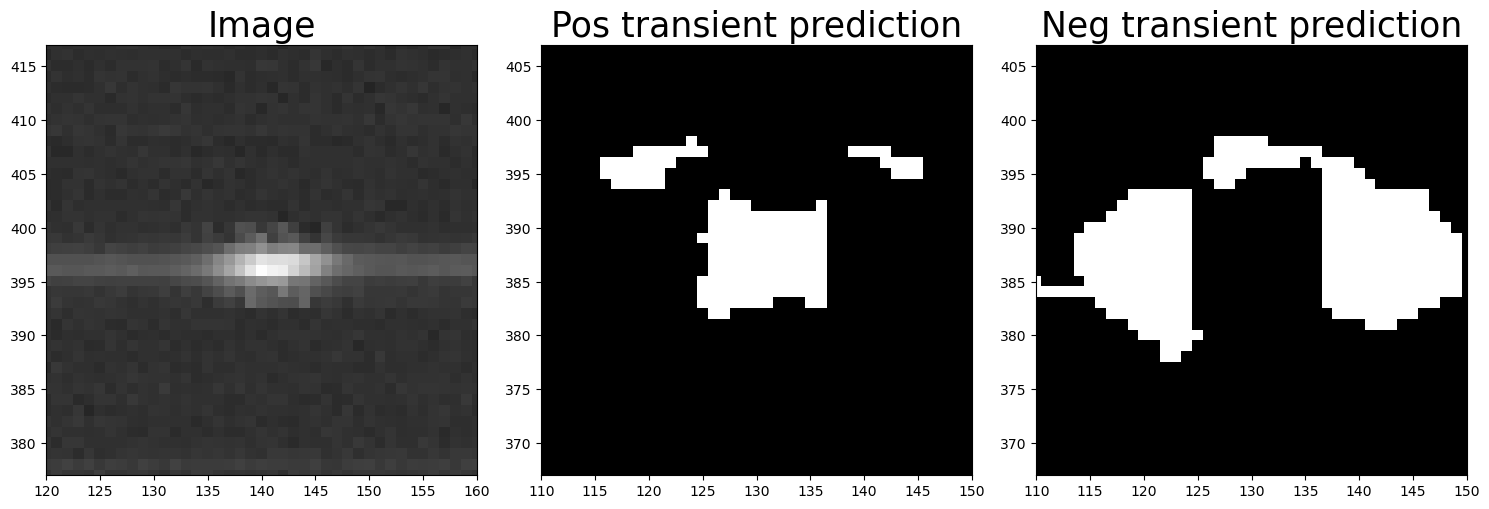

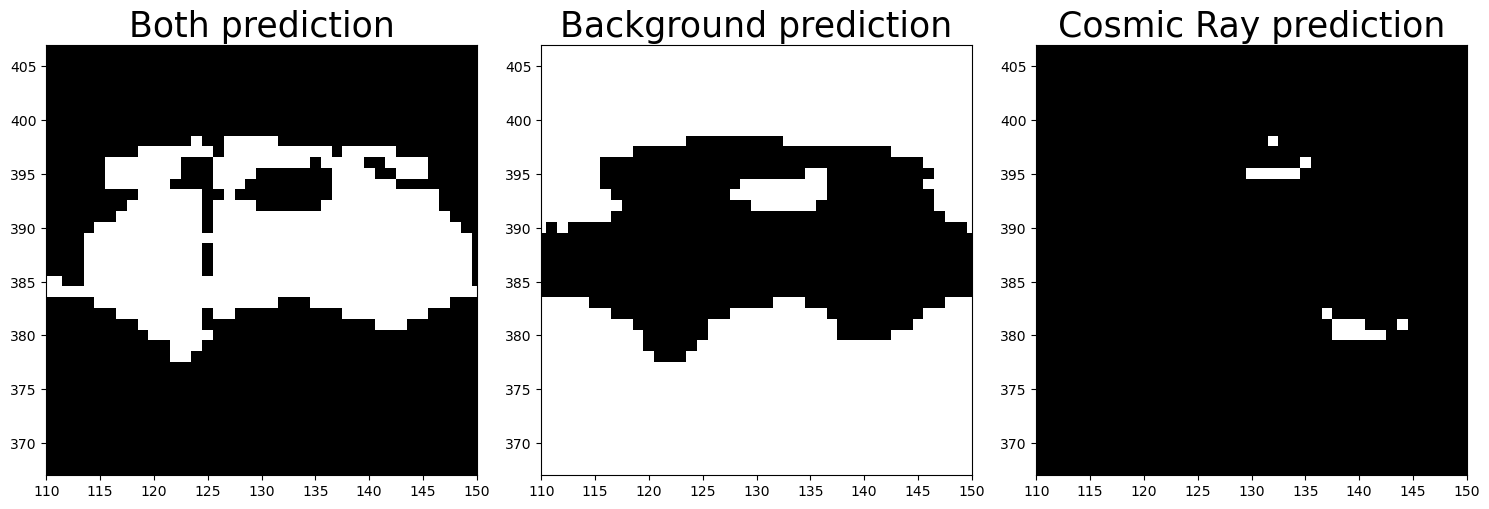

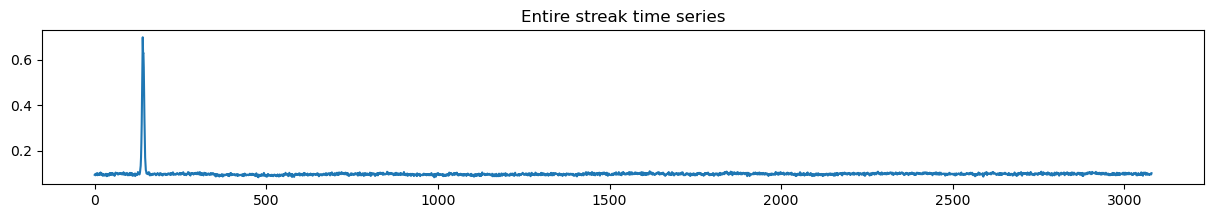

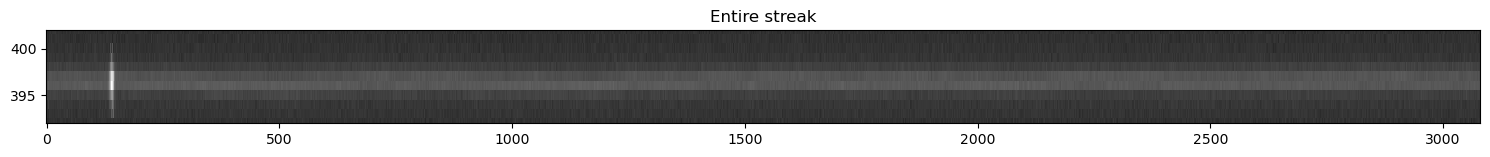

In [82]:
zoominthere2((130, 387), testimp, predsarray1, 0.5, 10)

In [72]:
pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_both = pimg_pos + pimg_neg

In [299]:
direcname = str(1020)
fname = "ztf_20221020297847_000449_zr_c15_x_0002.fits.fz"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)
path = fpath + fname
hdul = fits.open(path)
file1_array = hdul[1].data

In [298]:
# image2 =  np.load('/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020297847_000449_zr_c15_x_0002.


predsarray2 = np.load(
    "/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020297847_000449_zr_c15_x_0002._extraction_predsarray_1_predsarray.npy"
)

In [281]:
predsarray.shape

(9339120, 5)

In [83]:
pimg_pos = predsarray1[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_bg = predsarray1[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_streak = predsarray1[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_neg = predsarray1[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_cr = predsarray1[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_both = pimg_pos + pimg_neg

In [92]:
L_thr = pimg_pos > 0.9999
labs, nlabs = snm.label(L_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

(110.0, 150.0)

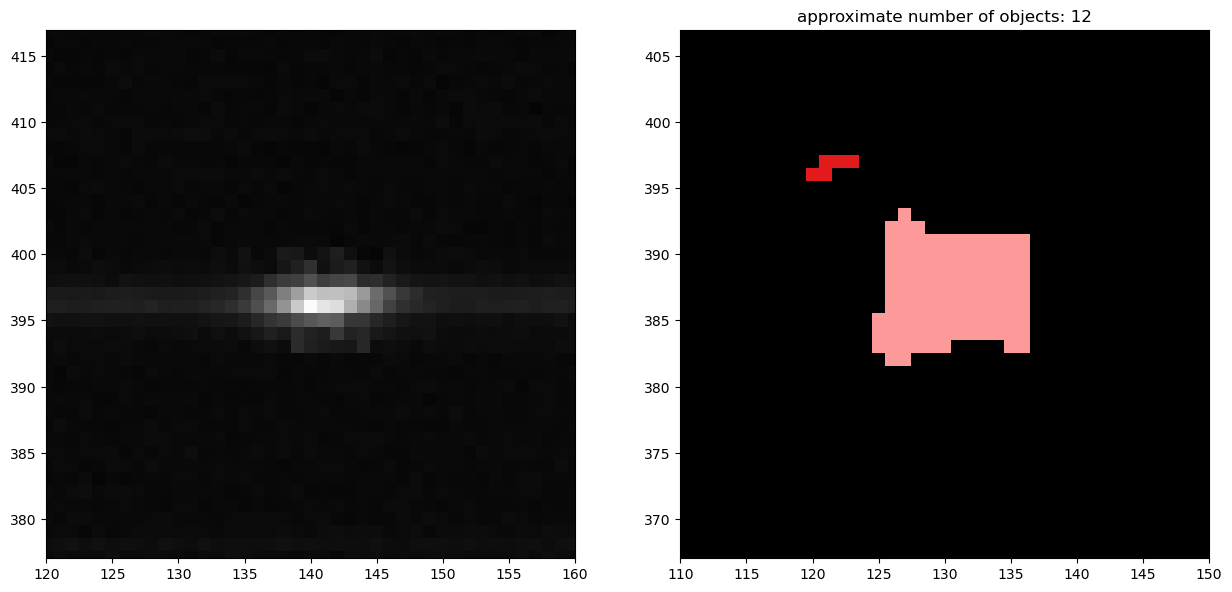

In [95]:
# -- display thresholded image and labels

row, col = (130, 387)
fig, ax = plt.subplots(1, 2, figsize=(15, 10))

ax[0].imshow(testimp.T)
ax[1].imshow(labs, cmap="Paired", alpha=L_thr.astype(float))
# otherwise "none" and "lowest numbered object" will be the same
# slpha is a float between 0 and 1, it's opaqueness

ax[1].set_facecolor("black")
ax[1].set_title("approximate number of objects: {0}".format(nlabs))

ax[0].set_ylim(col - 20 + wid, col + 20 + wid)
ax[0].set_xlim(row - 20 + wid, row + 20 + wid)

ax[1].set_ylim(col - 20, col + 20)
ax[1].set_xlim(row - 20, row + 20)

In [129]:
def zoominthere_five(loc, image, predsarray, thr, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    nrow, ncol = image.shape
    wid = 10
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_both = pimg_pos + pimg_neg

    pos_thr = pimg_pos > thr
    pos_labs, nlabs = snm.label(pos_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    neg_thr = pimg_neg > thr
    pos_labs, nlabs = snm.label(neg_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    both_thr = pimg_both > thr
    pos_labs, nlabs = snm.label(both_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    # print(pimg_both)

    wid = offset
    fig, ax = plt.subplots(1, 4, figsize=(15, 5))
    row, col = loc
    print("Threshold: ", thr)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image", fontsize=25)
    ax[1].imshow(pos_thr, cmap="Paired", alpha=pos_thr.astype(float))
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Brightening \ntransient prediction", fontsize=25)
    ax[2].imshow(neg_thr, cmap="Paired", alpha=neg_thr.astype(float))
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Dimming \ntransient prediction", fontsize=25)
    # plt.colorbar()
    # ax[1].plot((image[:,int(col+wid)]+image[:,int(col+wid)+1]+image[:,int(col+wid)-1])/3)
    # ax[1].set_xlim(row-20+wid,row+20+wid)
    # ax[1].set_title("Time series average of image row "
    #                 +str(int(col+wid))
    #                +" and adjacent")

    ax[3].imshow(both_thr, cmap="Paired", alpha=both_thr.astype(float))
    ax[3].set_ylim(col - 20, col + 20)
    ax[3].set_xlim(row - 20, row + 20)
    ax[3].set_title("Combined \nprediction", fontsize=25)
    for axis in ax:
        axis.set_xticks([])
        axis.set_yticks([])
        axis.set_facecolor("black")

    plt.tight_layout()
    plt.show()

Threshold:  0.9999


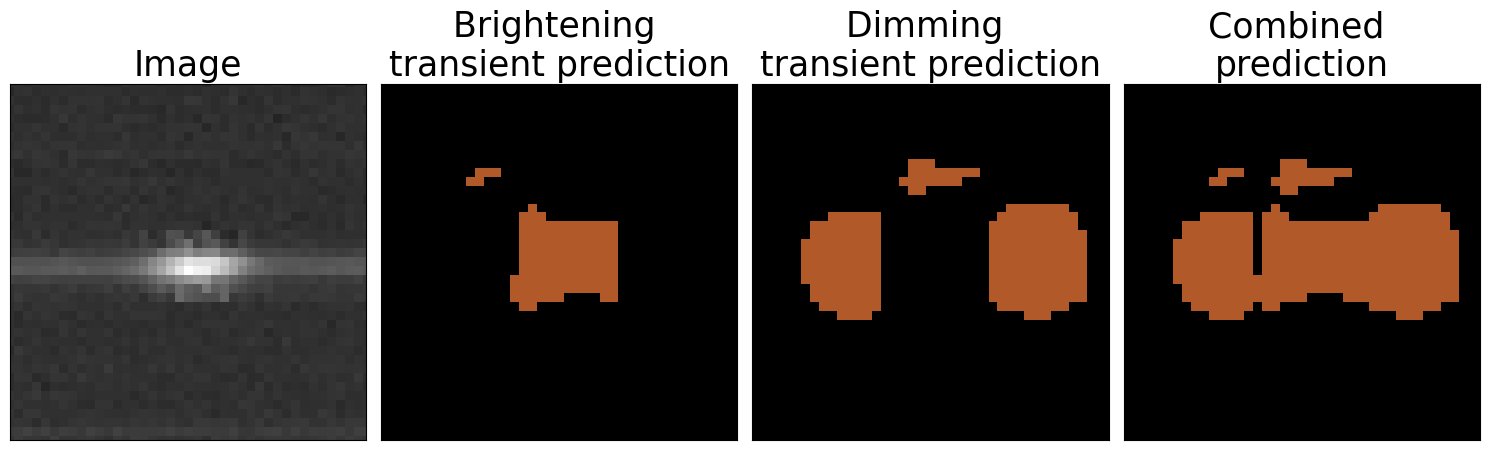

In [130]:
zoominthere_five((130, 387), testimp, predsarray1, 0.9999, 10)

Threshold:  0.9999


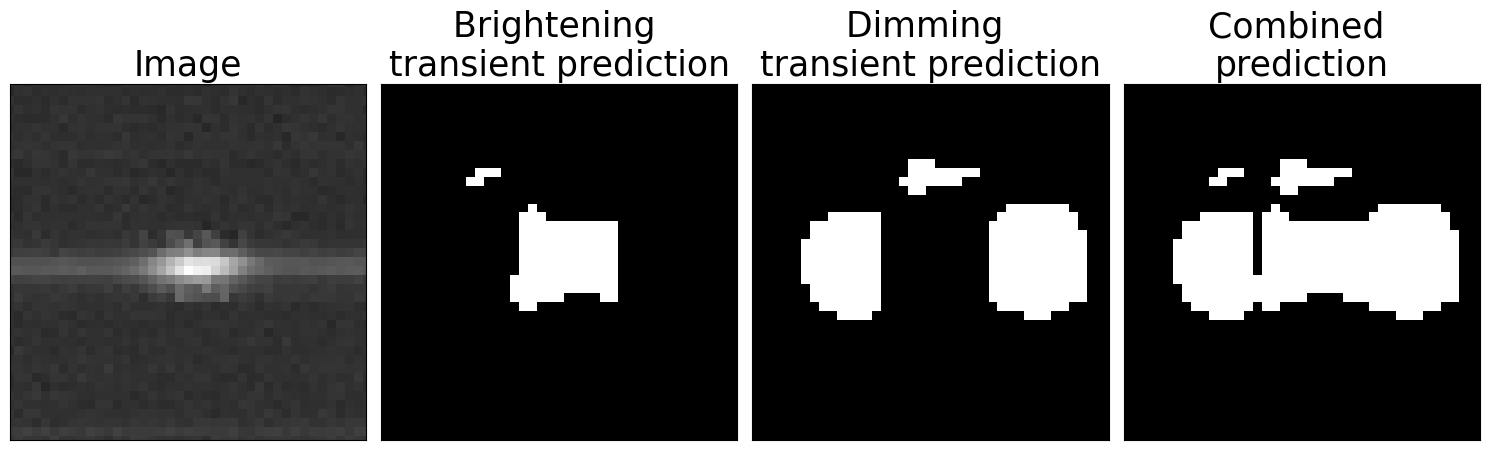

In [134]:
zoominthere_four((130, 387), testimp, predsarray1, 0.9999, 10)

Threshold:  0


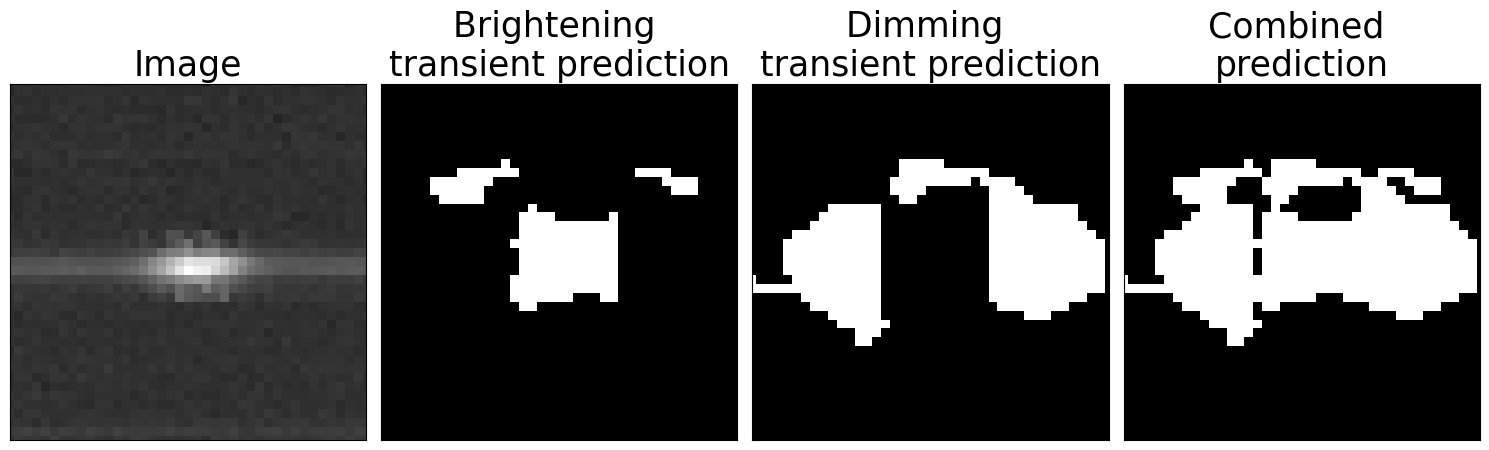

In [147]:
zoominthere_max((130, 387), testimp, predsarray1, 0, 10)

In [131]:
def zoominthere_four(loc, image, predsarray, thr, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    nrow, ncol = image.shape
    wid = 10
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)

    pimg_both = pimg_pos + pimg_neg
    # print(pimg_both)

    wid = offset
    fig, ax = plt.subplots(1, 4, figsize=(15, 5))
    row, col = loc
    print("Threshold: ", thr)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image", fontsize=25)
    ax[1].imshow((pimg_pos > thr))
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Brightening \ntransient prediction", fontsize=25)
    ax[2].imshow((pimg_neg > thr))
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Dimming \ntransient prediction", fontsize=25)
    # plt.colorbar()
    # ax[1].plot((image[:,int(col+wid)]+image[:,int(col+wid)+1]+image[:,int(col+wid)-1])/3)
    # ax[1].set_xlim(row-20+wid,row+20+wid)
    # ax[1].set_title("Time series average of image row "
    #                 +str(int(col+wid))
    #                +" and adjacent")

    ax[3].imshow((pimg_both > thr))
    ax[3].set_ylim(col - 20, col + 20)
    ax[3].set_xlim(row - 20, row + 20)
    ax[3].set_title("Combined \nprediction", fontsize=25)
    for axis in ax:
        axis.set_xticks([])
        axis.set_yticks([])

    plt.tight_layout()
    plt.show()

In [145]:
def zoominthere_max(loc, image, predsarray, thr, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    nrow, ncol = image.shape
    wid = 10
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_both = pimg_pos + pimg_neg

    pos_thr = pimg_pos > (pimg_bg + pimg_streak + pimg_cr + pimg_neg)
    pos_labs, nlabs = snm.label(pos_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    neg_thr = pimg_neg > (pimg_bg + pimg_streak + pimg_cr + pimg_pos)
    pos_labs, nlabs = snm.label(neg_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    both_thr = pos_thr + neg_thr
    pos_labs, nlabs = snm.label(both_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    # print(pimg_both)

    wid = offset
    fig, ax = plt.subplots(1, 4, figsize=(15, 5))
    row, col = loc
    print("Threshold: ", thr)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image", fontsize=25)
    ax[1].imshow(pos_thr)
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Brightening \ntransient prediction", fontsize=25)
    ax[2].imshow(neg_thr)
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Dimming \ntransient prediction", fontsize=25)
    # plt.colorbar()
    # ax[1].plot((image[:,int(col+wid)]+image[:,int(col+wid)+1]+image[:,int(col+wid)-1])/3)
    # ax[1].set_xlim(row-20+wid,row+20+wid)
    # ax[1].set_title("Time series average of image row "
    #                 +str(int(col+wid))
    #                +" and adjacent")

    ax[3].imshow(both_thr)
    ax[3].set_ylim(col - 20, col + 20)
    ax[3].set_xlim(row - 20, row + 20)
    ax[3].set_title("Combined \nprediction", fontsize=25)
    for axis in ax:
        axis.set_xticks([])
        axis.set_yticks([])
        # axis.set_facecolor("black")

    plt.tight_layout()
    plt.show()